# Customer Analytics: RFM, cohortes y LTV vs CAC

**Toda la parte de Python del proyecto (DS4B, Caso Final #2), corregida y explicada paso a paso.**

**Datos:** `clientes_1224.csv` (20.688 clientes con sus datos sociodemográficos y su coste de adquisición, CAC) y `productos_1224.csv` (78.266 líneas de compra de 2023).

## La idea del proyecto

Una empresa quiere saber **quiénes son sus clientes, cuánto valen y si le compensa lo que paga por captarlos**. Para responder se combinan tres técnicas clásicas de Customer Analytics:

| Técnica | Pregunta que responde | Resultado |
|---|---|---|
| **RFM** (*Recency, Frequency, Monetary*) | ¿Qué tipo de cliente es cada uno según cómo compra? | Segmentos con nombre (Campeones, En Riesgo...) y campañas para cada uno |
| **Cohortes** | ¿Cuántos clientes siguen comprando mes a mes después de su primera compra? | Tabla de retención |
| **LTV vs CAC** | ¿Cuánto deja un cliente en sus primeros 6 meses y cuándo recupera lo que costó captarlo? | Punto muerto por perfil de cliente |

Al final se generan los **tablones** (tablas planas) que alimentan el dashboard de Tableau.

## Qué reúne este notebook

La parte de Python estaba repartida en 5 notebooks. Aquí están todos juntos, en el mismo orden:

| Notebook original | Dónde está ahora |
|---|---|
| `01_EDA.ipynb` | Paso 2: exploración y limpieza |
| `02_RFM.ipynb` | Paso 3: RFM y segmentos |
| `03_Cohortes.ipynb` | Paso 4: cohortes y retención |
| `04_LTV.ipynb` | Paso 5: LTV, CAC y planes de acción |
| `05_Script_final.ipynb` (había dos copias casi iguales) | Paso 6: tablones para Tableau |

Se conserva **todo el análisis original** (cada consulta, cada gráfico y cada conclusión). Donde había un error se explica qué fallaba y cómo se corrige; esos puntos aparecen marcados como **Corrección**. Los añadidos que no estaban en el original aparecen como **Mejora**.

## Errores encontrados y corregidos

| # | Dónde | Qué fallaba | Consecuencia | Corrección |
|---|---|---|---|---|
| 1 | 01_EDA | La celda que guarda `clientes_final.csv` y `productos_final.csv` se ejecutó **justo después de cargar los datos** (contador de ejecución 3), antes de limpiar nada | Los archivos `_final` eran una copia de los originales: sin `Total_Venta`, con la fecha como texto y **con los nulos sin imputar**. Por eso en 02 había que volver a leer la fecha y recalcular `Total_Venta`, y en 04 aparecen clientes con Ocupación `NaN` | Se guarda al final de la limpieza y se comprueba lo guardado |
| 2 | 01_EDA | "Venta media por transacción" dividía entre `ID_Transaccion.count()`, que cuenta **líneas**, no transacciones | Salía 27,44 €, que es la venta media por **línea de producto** | Dividir entre el número de transacciones distintas (~49 €) |
| 3 | 01_EDA | No se detectó que **97 `ID_Transaccion` están repetidos entre clientes distintos** | Un ID no identifica una compra por sí solo | Se documenta; la *Frequency* del RFM no se ve afectada porque se cuenta por cliente |
| 4 | 02_RFM | Comentario "más de 10 compras" con código `>= 10` | Se cuentan clientes con 10 o más | Se corrige el texto |
| 5 | 02_RFM | Los cortes de *Frequency* `[1, 2, 4, 6, 9, máx]` dan la misma nota (1) a quien compró 1 vez y a quien compró 2 | El 76 % de los clientes tiene f = 1, y "Dudosos" (lo que no encaja en ningún segmento) se queda con el 42 % | Se mantiene la segmentación (es la del dashboard) pero se explica y se desglosa "Dudosos" |
| 6 | 02_RFM | Las campañas mezclan segmentos: "Clientes Rentables" está en dos campañas y "Dudosos" se trata como inactivo aunque muchos compraron hace poco | Campañas que se pisan y mensajes equivocados | Se cuantifica y se explica |
| 7 | 04_LTV | El LTV medio era la **media simple** de las 7 cohortes (101,41 €), calculada además con la retención **redondeada** | Pesa igual una cohorte de 1.168 clientes que una de 3.114. Es el mismo error que ya se explica en 03 para la retención | LTV ponderado = 102,76 €, que coincide con el del script final |
| 8 | 04_LTV | El LTV y el punto muerto se calculan con **ventas**, no con **margen**, aunque `Coste_Unitario` está en los datos | Con ventas el cliente "se paga" en el mes 2. Con margen, a los 6 meses deja 30,9 € frente a un CAC de 69,4 €: **todavía no se ha pagado** | Se añade el LTV de margen |
| 9 | 04_LTV | Los bucles por Nivel Educativo y Ocupación incluían la categoría `NaN` (por el error 1) | Gráficos vacíos | Con los datos ya imputados aparece "Desconocido" como una categoría más |
| 10 | 04_LTV | **Error de cálculo grave.** "Error real" = \|ltv_real − media\| y "error predicho" = \|ltv_predicho − media\|. El segundo no compara la predicción con la realidad | Se concluía que el modelo reducía el error de 74,1 a 18,7 €. En realidad lo reduce de 74,3 a 73,5 € (un 1 %) | Se compara \|real − predicho\| con \|real − media\| |
| 11 | 04_LTV | El "LTV predicho" se calculaba con datos que **incluían a la propia cohorte 2023-06** que luego se evalúa | El modelo "veía" las respuestas del examen (*data leakage*) | Se entrena con las otras 6 cohortes |
| 12 | 05_Script | `Segmento.value_counts()` se hacía sobre `tablon_analitico`, que tiene **una fila por línea de compra** | Salía "26.874 Dudosos" cuando son 5.791 clientes | Se cuenta sobre `tablon_cliente` |
| 13 | 05_Script | Las celdas se ejecutaron **fuera de orden** (contadores 15, 16, 17, 18, 5, 6, 6, 7...) | La tabla `tablon_cliente` que se ve guardada muestra "Dudosos" en todos los clientes porque viene de una ejecución anterior. No coincide con lo que calcula el código | El notebook se ejecuta de principio a fin |
| 14 | 05_Script | El RFM usa **todo 2023** (20.688 clientes) y el LTV solo la **ventana de 6 meses** de las cohortes ene-jul (14.367) | En el tablón conviven dos periodos distintos sin avisarlo, y los 6.321 clientes de ago-dic se quedan fuera | Se documenta en el propio tablón |
| 15 | 05_Script | Exportación con `decimal=','` y separador `,` | Para no romper las columnas, pandas mete cada número entre comillas (`"65,16"`), y algunas herramientas lo leen como texto | Separador `;` con decimal `,`, el estándar español |
| 16 | 05_Script | `tablon_cliente` tenía `ID_Cliente` como **índice** y se exportaba con `index=False` | El `tablon_cliente.csv` se quedaba **sin la columna `ID_Cliente`** | `.reset_index()` antes de exportar |
| 17 | 05_Script | Exportaciones repetidas y una celda `sys.executable` que muestra la ruta de tu usuario de Windows | Ruido, y un dato personal en un portfolio público | Se eliminan |

## Cómo usar este notebook

1. Pon este notebook en la misma carpeta que contiene `00_Datasets/` (con `clientes_1224.csv` y `productos_1224.csv` dentro), igual que en el proyecto original.
2. Ejecuta **Kernel → Restart & Run All**. Todo se ejecuta en orden, de arriba abajo, sin saltos.
3. Librerías: `pandas`, `numpy`, `matplotlib`, `squarify` (si no la tienes: `pip install squarify`).

## 1. Preparación

Se importan las librerías y se fija la carpeta de datos **en un solo sitio** (`RUTA`). En el original la ruta `'00_Datasets/...'` estaba escrita a mano en cada lectura y cada escritura. Si cambias de carpeta, aquí solo hay que tocar una línea.

`pathlib.Path` permite construir rutas con `/` que funcionan igual en Windows, Mac y Linux.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import squarify

RUTA = Path('00_Datasets')

# Mostrar más columnas al imprimir tablas anchas
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

print('pandas', pd.__version__)

pandas 3.0.5


## 2. EDA: exploración y limpieza (`01_EDA`)

El EDA (*Exploratory Data Analysis*) es la fase en la que se conoce el dato antes de analizarlo: qué columnas hay, de qué tipo son, si hay nulos, duplicados o valores raros. Las decisiones que se toman aquí (qué se imputa y qué se da por bueno) afectan a todo lo que viene después.

### 2.1 Carga de datos

In [2]:
# Carga de datos
productos = pd.read_csv(RUTA / 'productos_1224.csv')
clientes = pd.read_csv(RUTA / 'clientes_1224.csv')

productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08


Cada fila de `productos` es una **línea de compra**: un producto concreto dentro de una transacción. Si un cliente compra 3 productos distintos en un mismo ticket, aparecen 3 filas con el mismo `ID_Transaccion`.

### 2.2 Estructura y estadísticos

In [3]:
productos.info()

<class 'pandas.DataFrame'>
RangeIndex: 78266 entries, 0 to 78265
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Cliente          78266 non-null  int64  
 1   Fecha               78266 non-null  str    
 2   ID_Transaccion      78266 non-null  int64  
 3   Categoria_Producto  78266 non-null  str    
 4   Producto            78266 non-null  str    
 5   Coste_Unitario      78266 non-null  float64
 6   Cantidad            78266 non-null  float64
 7   Precio_Unitario     78266 non-null  float64
dtypes: float64(3), int64(2), str(3)
memory usage: 4.8 MB


`Fecha` se lee como texto (`str`). Más abajo se convierte a fecha, porque si no, no se pueden calcular días transcurridos ni extraer el mes.

`describe(include='all')` resume todas las columnas: para las numéricas da media, desviación y cuartiles; para las de texto, valores únicos (*unique*), el más frecuente (*top*) y cuántas veces aparece (*freq*).

In [4]:
productos.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID_Cliente,78266.0,NaN,NaN,NaN,11427.671147,6341.471309,1.0,6003.0,11684.0,16912.75,22625.0
Fecha,78266,363,2023-02-11,418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_Transaccion,78266.0,NaN,NaN,NaN,30741.936984,19354.549625,1.0,12943.25,29953.0,47872.0,64682.0
Categoria_Producto,78266,181,N8U,7406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Producto,78266,4550,UNJKW,1519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Coste_Unitario,78266.0,NaN,NaN,NaN,5.630948,5.780719,0.31,2.4,4.05,6.55,79.93
Cantidad,78266.0,NaN,NaN,NaN,3.521772,1.532599,1.0,3.0,3.0,4.0,20.0
Precio_Unitario,78266.0,NaN,NaN,NaN,8.057494,8.091848,0.38,3.63,5.94,9.35,141.54


### 2.3 Identificadores

In [5]:
productos.ID_Cliente.nunique()

20688

Hay 20.688 clientes distintos, pero el ID máximo es 22.625. Los IDs no son correlativos: en algún momento se eliminaron registros.

In [6]:
productos.ID_Transaccion.nunique()

43547

Pasa lo mismo con las transacciones: hay 43.547 IDs distintos.

**Mejora: ¿un ID de transacción pertenece siempre a un único cliente?** En un ticket real debería ser así. Se comprueba:

In [7]:
clientes_por_transaccion = productos.groupby('ID_Transaccion')['ID_Cliente'].nunique()
trans_compartidas = clientes_por_transaccion[clientes_por_transaccion > 1]
print('IDs de transacción con más de un cliente:', len(trans_compartidas))
print('Fechas distintas dentro de un mismo ID:', productos.groupby('ID_Transaccion')['Fecha'].nunique().max())

# Ejemplo de uno de esos IDs
productos[productos.ID_Transaccion == trans_compartidas.index[0]]

IDs de transacción con más de un cliente: 97
Fechas distintas dentro de un mismo ID: 1


,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
14370,4448,2023-01-12,1820,VQD,XOII4,3.14,4.0,6.03
14371,4448,2023-01-12,1820,1VL,23FFF,5.81,4.0,10.79
78196,17130,2023-01-12,1820,1VL,23FFF,5.81,4.0,10.79


**97 IDs de transacción aparecen en dos clientes distintos** (siempre con la misma fecha). Es un defecto del dato que no se detectó en el original. Lo prudente es identificar una compra por la pareja **(cliente, transacción)**, no solo por el ID.

Para el RFM no cambia nada: la *Frequency* se calcula **dentro de cada cliente** (`groupby('ID_Cliente')['ID_Transaccion'].nunique()`) y ahí cada ID cuenta una vez. Pero sí afecta a la "venta media por transacción" (apartado 2.10).

### 2.4 Variables categóricas

In [8]:
# Para conocer las frecuencias de la categoría de productos
productos.Categoria_Producto.value_counts()

Categoria_Producto
N8U    7406
R6E    3810
P42    3740
0H2    3315
H15    2308
       ... 
663       2
VD0       1
HXR       1
QON       1
NLS       1
Name: count, Length: 181, dtype: int64

In [9]:
# Para conocer las frecuencias de los productos
productos.Producto.value_counts()

Producto
UNJKW    1519
COWU2     590
OV1P9     579
M6J9W     494
CZUZX     475
         ... 
Q3HUB       1
9PIHP       1
YE2M6       1
QI61R       1
0FNQX       1
Name: count, Length: 4550, dtype: int64

Hay 181 categorías y 4.550 productos, con códigos anonimizados. La distribución es muy desigual: la categoría N8U tiene 7.406 líneas y varias tienen solo 1.

### 2.5 Variables numéricas

In [10]:
# Ahora, para el coste unitario
productos.Coste_Unitario.describe()

count    78266.000000
mean         5.630948
std          5.780719
min          0.310000
25%          2.400000
50%          4.050000
75%          6.550000
max         79.930000
Name: Coste_Unitario, dtype: float64

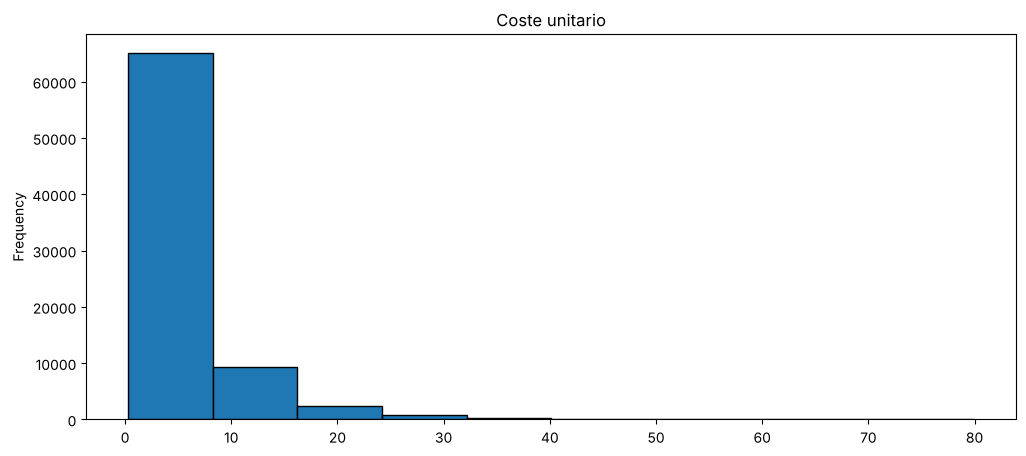

In [11]:
# Graficamos esta variable
productos.Coste_Unitario.plot(kind='hist', bins=10, figsize=(12, 5), edgecolor='black',
                              title='Coste unitario');

In [12]:
# Miramos, ahora, el precio unitario
productos.Precio_Unitario.describe()

count    78266.000000
mean         8.057494
std          8.091848
min          0.380000
25%          3.630000
50%          5.940000
75%          9.350000
max        141.540000
Name: Precio_Unitario, dtype: float64

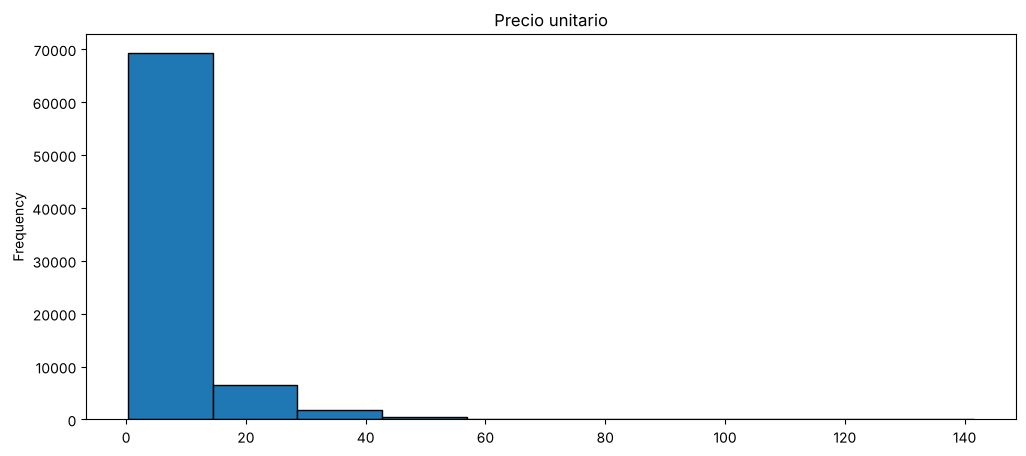

In [13]:
# Graficamos el precio unitario
productos.Precio_Unitario.plot(kind='hist', bins=10, figsize=(12, 5), edgecolor='black',
                               title='Precio unitario');

Las dos variables tienen **asimetría a la derecha**: la mayoría de productos cuestan pocos euros y unos pocos son mucho más caros. Por eso la media (8,06 €) queda por encima de la mediana (5,94 €).

In [14]:
# Analizamos ahora la cantidad
productos.Cantidad.value_counts()

Cantidad
3.0     26234
4.0     18926
2.0     14836
5.0      8914
1.0      3191
6.0      3167
7.0      1464
8.0       692
9.0       289
10.0      234
11.0      123
12.0       67
13.0       48
14.0       25
15.0       16
16.0       14
17.0       10
18.0        6
20.0        6
19.0        4
Name: count, dtype: int64

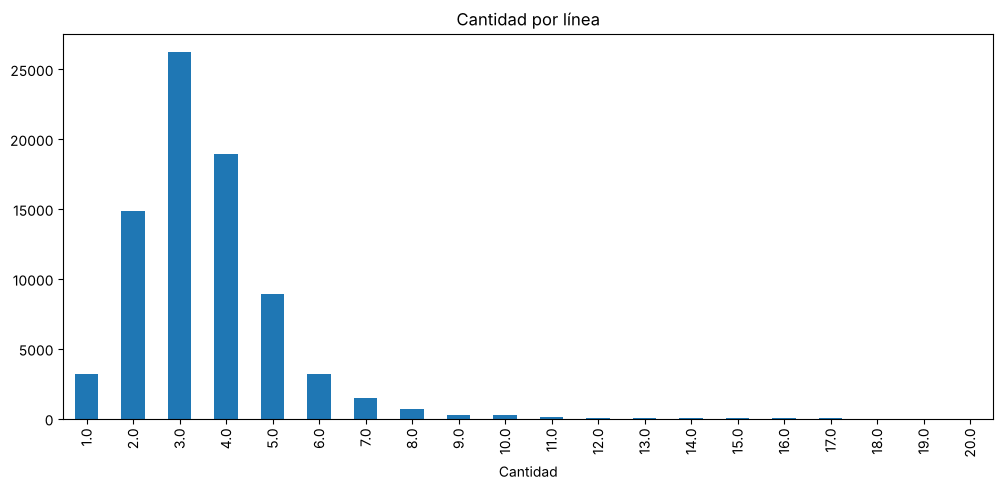

In [15]:
# Graficamos la variable cantidad
productos.Cantidad.value_counts().sort_index().plot(kind='bar', figsize=(12, 5), title='Cantidad por línea');

En el original el gráfico de barras salía ordenado por frecuencia (3, 4, 2, 5...). Con `.sort_index()` las barras quedan en orden 1, 2, 3..., que es más natural para una cantidad.

### 2.6 Atípicos

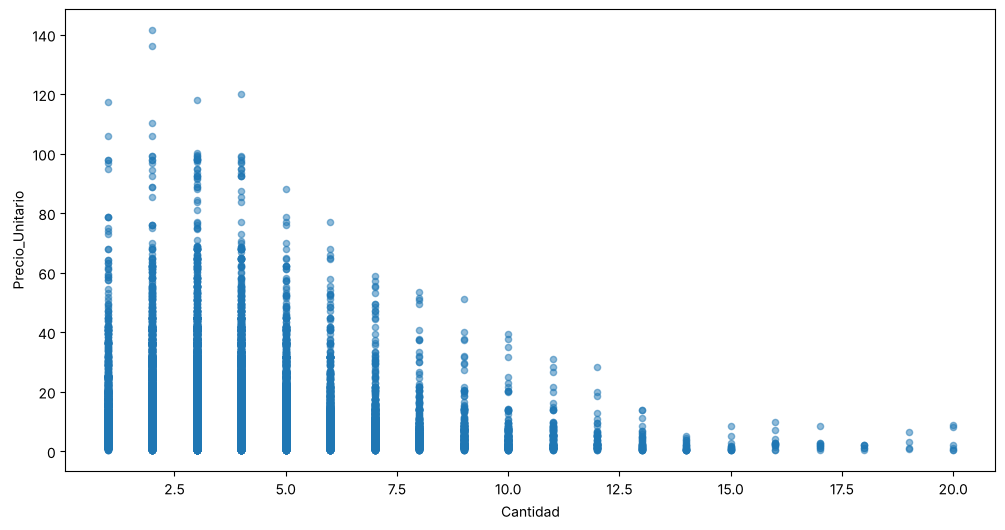

In [16]:
# Atípicos entre las variables cantidad y precio unitario
productos.plot.scatter(x='Cantidad', y='Precio_Unitario', alpha=0.5, figsize=(12, 6));

In [17]:
# Investigamos las cantidades de 16 productos o más y los precios unitarios de 110 € o más
productos[productos.Cantidad >= 16]

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
632,200,2023-02-04,5699,TW8,M93I3,1.32,17.0,1.69
2986,980,2023-04-20,19020,W41,ZWFSY,0.31,16.0,0.57
3708,1204,2023-02-18,8081,OWA,HOKUT,2.15,19.0,2.94
3710,1204,2023-02-18,8081,OWA,9PCYD,1.88,16.0,2.19
3859,1250,2023-03-10,11472,U5F,2SVKS,1.19,18.0,2.21
6969,2197,2023-03-08,11110,W41,ZWFSY,0.34,16.0,0.57
7554,2394,2023-01-20,3149,IEV,4FT32,1.30,16.0,2.14
8355,2615,2023-04-02,15601,RU6,ERYF4,6.14,20.0,8.21
11135,3509,2023-03-08,11060,FU5,W53F2,0.74,19.0,1.21
11140,3509,2023-05-05,21820,FU5,W53F2,0.90,17.0,1.21


In [18]:
productos[productos.Precio_Unitario >= 110]

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
23,10,2023-02-11,6893,SJS,UTE9R,63.19,2.0,110.31
57889,16736,2023-11-26,57692,V9H,YG3Q9,66.14,1.0,117.41
57926,16749,2023-12-13,61070,663,2BOK0,61.97,4.0,119.95
60202,17267,2023-03-14,12041,6BZ,09K06,78.56,3.0,117.96
70115,19886,2023-04-11,17352,6BZ,P35XJ,68.51,2.0,136.17
74293,21240,2023-03-18,12879,6BZ,NACZN,71.90,2.0,141.54


Se dan por válidos los registros de cantidad y precio unitario: son pocos, son coherentes (los precios altos son productos caros, no errores de tecleo) y no hay negativos.

**Mejora: comprobaciones de coherencia** que conviene hacer siempre con datos de ventas:

In [19]:
print('Líneas con precio menor que el coste (venta a pérdida):', (productos.Precio_Unitario < productos.Coste_Unitario).sum())
print('Cantidades no enteras:', (productos.Cantidad % 1 != 0).sum())
print('Valores negativos o cero:', (productos[['Coste_Unitario', 'Cantidad', 'Precio_Unitario']] <= 0).sum().sum())

Líneas con precio menor que el coste (venta a pérdida): 0
Cantidades no enteras: 0
Valores negativos o cero: 0


No hay ventas a pérdida, todas las cantidades son enteras y no hay negativos.

### 2.7 Nulos y duplicados

In [20]:
# Revisión nulos y duplicados en Productos
productos.isna().sum()

ID_Cliente            0
Fecha                 0
ID_Transaccion        0
Categoria_Producto    0
Producto              0
Coste_Unitario        0
Cantidad              0
Precio_Unitario       0
dtype: int64

In [21]:
productos.duplicated().sum()

np.int64(0)

No hay nulos ni filas duplicadas en `productos`.

### 2.8 Tipos de datos y nuevas variables

In [22]:
# Cambiamos la tipología de la variable Fecha
productos['Fecha'] = pd.to_datetime(productos['Fecha'])

# Creamos la variable Total_Venta (importe de cada línea)
productos['Total_Venta'] = productos['Cantidad'] * productos['Precio_Unitario']

# Mejora: margen bruto de cada línea (lo que queda después de pagar el producto)
productos['Margen'] = (productos['Precio_Unitario'] - productos['Coste_Unitario']) * productos['Cantidad']

- `Total_Venta` = cantidad × precio: lo que **paga** el cliente.
- `Margen` = (precio − coste) × cantidad: lo que **gana** la empresa con esa línea, antes de otros gastos. **Mejora:** no estaba en el original y se usa en el paso 5 para calcular el LTV con margen.

In [23]:
productos['Total_Venta'].describe()

count    78266.000000
mean        27.442467
std         30.120627
min          0.460000
25%         10.710000
50%         19.000000
75%         32.640000
max        479.800000
Name: Total_Venta, dtype: float64

In [24]:
productos['Total_Venta'].value_counts()

Total_Venta
13.50     568
6.33      483
27.00     445
20.25     438
18.00     403
         ... 
49.30       1
172.20      1
120.60      1
2.22        1
272.40      1
Name: count, Length: 6015, dtype: int64

In [25]:
productos.info()

<class 'pandas.DataFrame'>
RangeIndex: 78266 entries, 0 to 78265
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          78266 non-null  int64         
 1   Fecha               78266 non-null  datetime64[us]
 2   ID_Transaccion      78266 non-null  int64         
 3   Categoria_Producto  78266 non-null  str           
 4   Producto            78266 non-null  str           
 5   Coste_Unitario      78266 non-null  float64       
 6   Cantidad            78266 non-null  float64       
 7   Precio_Unitario     78266 non-null  float64       
 8   Total_Venta         78266 non-null  float64       
 9   Margen              78266 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(2), str(2)
memory usage: 6.0 MB


### 2.9 Margen medio del negocio

In [26]:
margen_pct = productos['Margen'].sum() / productos['Total_Venta'].sum() * 100
print(f'Margen bruto sobre ventas: {margen_pct:.1f} %')

Margen bruto sobre ventas: 30.1 %


De cada 100 € vendidos, unos 30 € son margen. Este dato es clave en el paso 5: el CAC se paga con el margen, no con las ventas.

### 2.10 Consultas básicas

**Corrección.** El original calculaba `Total_Venta.sum() / ID_Transaccion.count()`. Pero `count()` cuenta **filas no nulas**, es decir, líneas de producto (78.266), no transacciones. El 27,44 € que salía es la venta media **por línea**. Para la venta media **por transacción** hay que dividir entre el número de transacciones distintas, identificadas por la pareja (cliente, transacción) por lo visto en 2.3.

In [27]:
# Lo que calculaba el original: venta media por LÍNEA de producto
venta_media_linea = productos.Total_Venta.sum() / productos.ID_Transaccion.count()

# Lo correcto: venta media por TRANSACCIÓN (ticket)
n_transacciones = productos[['ID_Cliente', 'ID_Transaccion']].drop_duplicates().shape[0]
venta_media_transaccion = productos.Total_Venta.sum() / n_transacciones

print(f'Venta media por línea:       {venta_media_linea:.2f} €')
print(f'Transacciones distintas:     {n_transacciones}')
print(f'Venta media por transacción: {venta_media_transaccion:.2f} €')
print(f'Productos por transacción:   {len(productos) / n_transacciones:.2f}')

Venta media por línea:       27.44 €
Transacciones distintas:     43644
Venta media por transacción: 49.21 €
Productos por transacción:   1.79


In [28]:
# Cálculo de la venta media por cliente (en todo 2023)
productos.groupby('ID_Cliente').Total_Venta.sum().mean()

np.float64(103.81922660479506)

Un ticket medio ronda los 49 € (unos 1,8 productos) y un cliente gasta de media 103,82 € en todo el año.

### 2.11 Revisión de clientes

In [29]:
clientes.head()

,ID_Cliente,Fecha_Nacimiento,Genero,Codigo_Postal,Nivel_Educativo,Ocupacion,Tamano_Hogar,CAC
0,1,1969-11-23,Hombre,46001,Universitario,Empleado,4-5 personas,184.31
1,2,1973-08-07,Hombre,7003,Sin estudios,Empleado,1 persona,31.60
2,3,1967-06-03,Mujer,11001,Bachillerato,Estudiante,4-5 personas,29.33
3,4,1975-10-22,Hombre,38002,Bachillerato,Empleado,2-3 personas,63.67
4,5,1997-07-12,Mujer,28003,Universitario,Estudiante,2-3 personas,11.13


In [30]:
clientes.info()

<class 'pandas.DataFrame'>
RangeIndex: 20688 entries, 0 to 20687
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Cliente        20688 non-null  int64  
 1   Fecha_Nacimiento  20688 non-null  str    
 2   Genero            20688 non-null  str    
 3   Codigo_Postal     20688 non-null  int64  
 4   Nivel_Educativo   18721 non-null  str    
 5   Ocupacion         18293 non-null  str    
 6   Tamano_Hogar      19010 non-null  str    
 7   CAC               20688 non-null  float64
dtypes: float64(1), int64(2), str(5)
memory usage: 1.3 MB


In [31]:
clientes.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID_Cliente,20688.0,NaN,NaN,NaN,11151.335509,6579.245799,1.0,5472.75,10994.0,16758.25,22625.0
Fecha_Nacimiento,20688,11714,1978-11-06,1434,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genero,20688,2,Mujer,12886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Codigo_Postal,20688.0,NaN,NaN,NaN,25380.818784,14104.232564,3001.0,11003.0,28002.0,35003.0,50003.0
Nivel_Educativo,18721,5,Bachillerato,4937,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ocupacion,18293,5,Empleado,5797,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tamano_Hogar,19010,3,2-3 personas,14806,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CAC,20688.0,NaN,NaN,NaN,71.063981,80.247538,0.56,21.28,47.81,85.65,1876.77


In [32]:
clientes.ID_Cliente.nunique()

20688

In [33]:
# ¿Todos los clientes que compran están en la tabla de clientes, y al revés?
print('Clientes en productos que no están en clientes:', len(set(productos.ID_Cliente) - set(clientes.ID_Cliente)))
print('Clientes en clientes que no compran:', len(set(clientes.ID_Cliente) - set(productos.ID_Cliente)))

Clientes en productos que no están en clientes: 0
Clientes en clientes que no compran: 0


**Mejora:** se comprueba que las dos tablas casan. Los 20.688 clientes son exactamente los mismos en las dos, así que los `merge` posteriores no van a perder ni inventar clientes.

**Revisión de las variables**

In [34]:
# Revisamos la variable Tamano_Hogar; dropna=False hace que también se cuenten los nulos
clientes.Tamano_Hogar.value_counts(dropna=False)

Tamano_Hogar
2-3 personas    14806
4-5 personas     3231
NaN              1678
1 persona         973
Name: count, dtype: int64

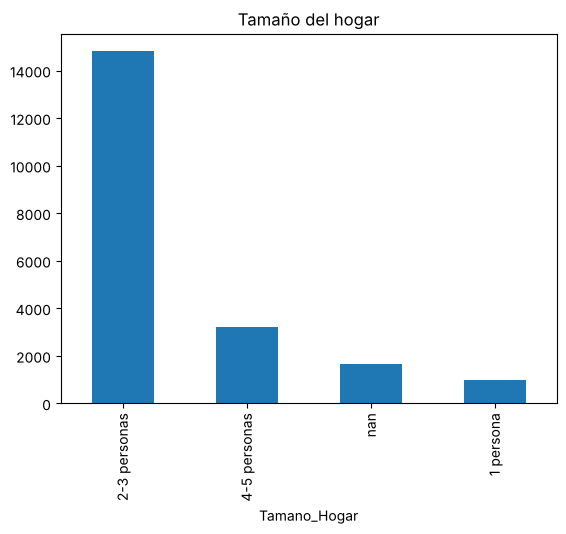

In [35]:
# Graficamos
clientes.Tamano_Hogar.value_counts(dropna=False).plot(kind='bar', title='Tamaño del hogar');

In [36]:
# Ahora revisaremos la variable Ocupación
clientes.Ocupacion.value_counts(dropna=False)

Ocupacion
Empleado       5797
Autónomo       5308
Desempleado    3281
Jubilado       2528
NaN            2395
Estudiante     1379
Name: count, dtype: int64

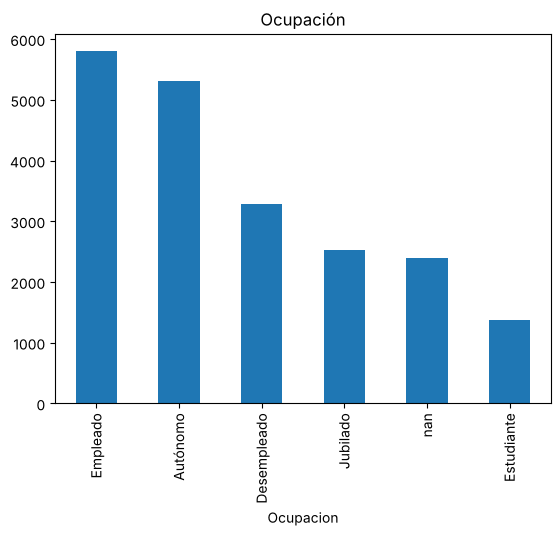

In [37]:
# Graficamos
clientes.Ocupacion.value_counts(dropna=False).plot(kind='bar', title='Ocupación');

In [38]:
# Analizamos ahora otra variable que tiene valores nulos, que es Nivel_Educativo
clientes.Nivel_Educativo.value_counts(dropna=False)

Nivel_Educativo
Bachillerato        4937
Máster              4772
Universitario       4473
Educación básica    3636
NaN                 1967
Sin estudios         903
Name: count, dtype: int64

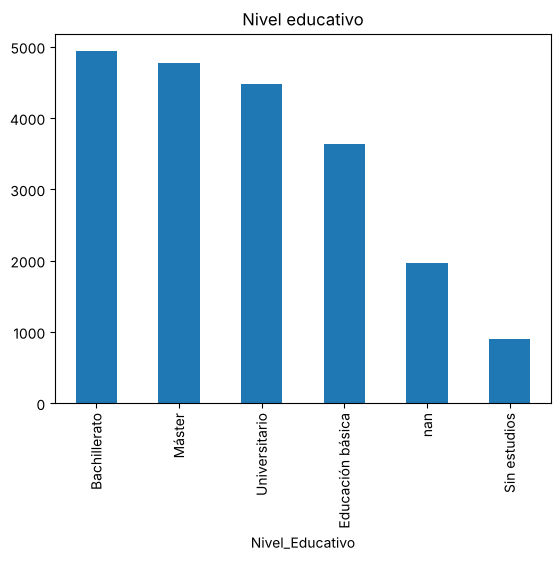

In [39]:
# Graficamos
clientes.Nivel_Educativo.value_counts(dropna=False).plot(kind='bar', title='Nivel educativo');

In [40]:
# Analizamos la variable Genero
clientes.Genero.value_counts(dropna=False)

Genero
Mujer     12886
Hombre     7802
Name: count, dtype: int64

In [41]:
# Variable Coste de Adquisición
clientes.CAC.describe()

count    20688.000000
mean        71.063981
std         80.247538
min          0.560000
25%         21.280000
50%         47.810000
75%         85.650000
max       1876.770000
Name: CAC, dtype: float64

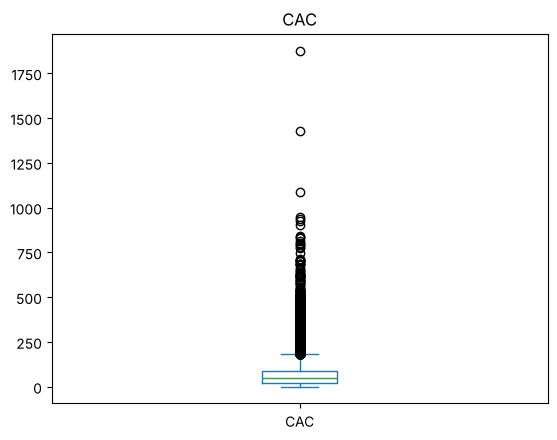

In [42]:
# Graficamos, para ver los valores que se salen de la distribución
clientes.CAC.plot(kind='box', title='CAC');

In [43]:
# Revisamos los clientes que estén por encima de los 1000 €
clientes[clientes.CAC > 1000]

,ID_Cliente,Fecha_Nacimiento,Genero,Codigo_Postal,Nivel_Educativo,Ocupacion,Tamano_Hogar,CAC
7457,8603,1989-05-09,Mujer,7001,Universitario,Empleado,4-5 personas,1089.83
12039,13940,1989-03-15,Hombre,11002,Universitario,Empleado,NaN,1876.77
17958,21208,1995-12-06,Hombre,50002,Universitario,Empleado,4-5 personas,1426.00


No se consideran atípicos estos tres valores: tienen el resto de información completa y coherente, así que son registros correctos (clientes captados con campañas caras).

Ojo: aunque no se eliminen, el CAC tiene una cola larga a la derecha (media 71,06 € frente a una mediana de 47,81 €). La media del CAC, que es la que se compara con el LTV en el paso 5, está "tirada hacia arriba" por esos clientes caros.

**Comprobación de nulos y duplicados**

In [44]:
clientes.isna().sum()

ID_Cliente             0
Fecha_Nacimiento       0
Genero                 0
Codigo_Postal          0
Nivel_Educativo     1967
Ocupacion           2395
Tamano_Hogar        1678
CAC                    0
dtype: int64

In [45]:
clientes.duplicated().sum()

np.int64(0)

**Corrección de datos**

- **Tamano_Hogar**: se imputa con la **moda** ("2-3 personas"), que tiene el 78 % de los valores conocidos. Imputar con la moda es razonable cuando una categoría domina tanto.
- **Ocupacion** y **Nivel_Educativo**: no hay una categoría claramente dominante (en Nivel Educativo, Bachillerato y Máster están casi empatados), así que los nulos pasan a una categoría **"Desconocido"**. Así no se inventa información y se puede ver si los clientes sin dato se comportan distinto.

In [46]:
# Imputamos Tamano_Hogar con la moda
moda_tamano_hogar = clientes.Tamano_Hogar.mode()[0]
print('Moda:', moda_tamano_hogar)
clientes['Tamano_Hogar'] = clientes['Tamano_Hogar'].fillna(moda_tamano_hogar)
clientes['Tamano_Hogar'].value_counts(dropna=False)

Moda: 2-3 personas


Tamano_Hogar
2-3 personas    16484
4-5 personas     3231
1 persona         973
Name: count, dtype: int64

In [47]:
# Ocupacion y Nivel_Educativo: NaN -> 'Desconocido'
clientes['Ocupacion'] = clientes['Ocupacion'].fillna('Desconocido')
clientes['Nivel_Educativo'] = clientes['Nivel_Educativo'].fillna('Desconocido')
clientes['Nivel_Educativo'].value_counts(dropna=False)

Nivel_Educativo
Bachillerato        4937
Máster              4772
Universitario       4473
Educación básica    3636
Desconocido         1967
Sin estudios         903
Name: count, dtype: int64

In [48]:
clientes['Ocupacion'].value_counts(dropna=False)

Ocupacion
Empleado       5797
Autónomo       5308
Desempleado    3281
Jubilado       2528
Desconocido    2395
Estudiante     1379
Name: count, dtype: int64

In [49]:
# Cambio de tipología de la variable fecha
clientes['Fecha_Nacimiento'] = pd.to_datetime(clientes['Fecha_Nacimiento'])
clientes.info()

<class 'pandas.DataFrame'>
RangeIndex: 20688 entries, 0 to 20687
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID_Cliente        20688 non-null  int64         
 1   Fecha_Nacimiento  20688 non-null  datetime64[us]
 2   Genero            20688 non-null  str           
 3   Codigo_Postal     20688 non-null  int64         
 4   Nivel_Educativo   20688 non-null  str           
 5   Ocupacion         20688 non-null  str           
 6   Tamano_Hogar      20688 non-null  str           
 7   CAC               20688 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 1.3 MB


**Consultas básicas**

In [50]:
# Coste de adquisición medio
clientes.CAC.mean()

np.float64(71.06398105181748)

### 2.12 Guardar los datos corregidos

**Corrección (error 1).** En el `01_EDA` original, la celda de guardado tiene el contador de ejecución **[3]**: se ejecutó justo después de cargar los datos, antes de limpiar nada. Las pistas de que los `_final` eran una copia sin tratar están en los otros notebooks:

- En `02_RFM`, `productos.info()` muestra 8 columnas (sin `Total_Venta`) y la `Fecha` como texto. Por eso hubo que releer con `parse_dates` y volver a calcular `Total_Venta`.
- En `04_LTV`, la tabla de la cohorte 2023-06 muestra clientes con **Ocupación `NaN`**, aunque en el EDA ya se habían convertido en "Desconocido".

Por eso aquí se guarda **al final** de la limpieza y se **relee lo guardado** para comprobarlo.

Al guardar en CSV las fechas se convierten en texto. Por eso, al leer un `_final`, siempre hay que usar `parse_dates`.

In [51]:
clientes.to_csv(RUTA / 'clientes_final.csv', index=False)
productos.to_csv(RUTA / 'productos_final.csv', index=False)

# Comprobación: lo que se ha guardado es lo que se ha limpiado
comprobar_c = pd.read_csv(RUTA / 'clientes_final.csv', parse_dates=['Fecha_Nacimiento'])
comprobar_p = pd.read_csv(RUTA / 'productos_final.csv', parse_dates=['Fecha'])
print('Nulos en clientes_final:', comprobar_c.isna().sum().sum())
print('Columnas de productos_final:', list(comprobar_p.columns))
print('Tipo de Fecha:', comprobar_p['Fecha'].dtype)

Nulos en clientes_final: 0
Columnas de productos_final: ['ID_Cliente', 'Fecha', 'ID_Transaccion', 'Categoria_Producto', 'Producto', 'Coste_Unitario', 'Cantidad', 'Precio_Unitario', 'Total_Venta', 'Margen']
Tipo de Fecha: datetime64[us]


**Código EDA unificado** (las transformaciones que cambian los datos, sin las consultas):

```python
productos = pd.read_csv(RUTA / 'productos_1224.csv', parse_dates=['Fecha'])
clientes = pd.read_csv(RUTA / 'clientes_1224.csv', parse_dates=['Fecha_Nacimiento'])

productos['Total_Venta'] = productos['Cantidad'] * productos['Precio_Unitario']
productos['Margen'] = (productos['Precio_Unitario'] - productos['Coste_Unitario']) * productos['Cantidad']

clientes['Tamano_Hogar'] = clientes['Tamano_Hogar'].fillna(clientes['Tamano_Hogar'].mode()[0])
clientes['Ocupacion'] = clientes['Ocupacion'].fillna('Desconocido')
clientes['Nivel_Educativo'] = clientes['Nivel_Educativo'].fillna('Desconocido')
```

## 3. RFM: segmentación de clientes (`02_RFM`)

El RFM resume a cada cliente en tres números:

| Letra | Métrica | Cómo se calcula | Mejor cuanto... |
|---|---|---|---|
| **R** | *Recency* (recencia) | Días desde su última compra hasta la fecha más reciente del dataset | **menor** (compró hace poco) |
| **F** | *Frequency* (frecuencia) | Número de transacciones distintas | **mayor** |
| **M** | *Monetary* (valor) | Suma de lo que ha gastado | **mayor** |

Después se puntúa cada métrica de 1 a 5 y, combinando las tres notas, se asigna un segmento.

No hace falta releer `productos_final.csv`: los datos limpios ya están en memoria. En el original se releían (y por el error 1 llegaban sin limpiar).

### 3.1 Recency

In [52]:
# Obtenemos la última fecha de transacción del dataset (la fecha de referencia del análisis)
fecha_max = productos['Fecha'].max()
fecha_max

Timestamp('2023-12-31 00:00:00')

In [53]:
# Recencia en días para cada cliente: fecha de referencia - fecha de su última compra
rfm = productos.groupby('ID_Cliente').agg(Recency=('Fecha', lambda x: (fecha_max - x.max()).days))
rfm

,Recency
ID_Cliente,
1,344
2,195
3,364
4,52
5,179
...,...
22621,21
22622,15
22623,10


Cómo funciona: `groupby('ID_Cliente')` separa las compras de cada cliente; `x.max()` es su última fecha; restarla de `fecha_max` da un `Timedelta`, y `.days` lo pasa a días. `agg(Recency=(columna, función))` es la "agregación con nombre": crea una columna llamada `Recency`.

In [54]:
rfm.describe()

,Recency
count,20688.000000
mean,168.527020
std,114.364149
min,0.000000
25%,58.000000
50%,166.000000
75%,275.000000
max,364.000000


In [55]:
# Media de tiempo que ha pasado desde la última compra de los clientes
rfm.mean()

Recency    168.52702
dtype: float64

In [56]:
# Número de clientes que han hecho una compra en el último mes
len(rfm[rfm['Recency'] <= 30])

3171

In [57]:
# Número de clientes que han hecho una compra en los últimos 90 días
len(rfm[rfm['Recency'] <= 90])

7045

In [58]:
# Clientes que no han comprado en los últimos 6 meses (180 días o más)
clientes_inactivos = rfm[rfm['Recency'] >= 180].shape[0]
total_clientes = rfm.shape[0]

print('Clientes sin comprar en 180 días o más:', clientes_inactivos)
print(f'Porcentaje: {clientes_inactivos / total_clientes * 100:.2f} %')

Clientes sin comprar en 180 días o más: 9835
Porcentaje: 47.54 %


Casi la mitad de los clientes (47,5 %) lleva 6 meses o más sin comprar.

### 3.2 Frequency

In [59]:
# Número de transacciones distintas de cada cliente
rfm['Frequency'] = productos.groupby('ID_Cliente')['ID_Transaccion'].nunique()
rfm

,Recency,Frequency
ID_Cliente,,
1,344,1
2,195,2
3,364,1
4,52,2
5,179,5
...,...,...
22621,21,1
22622,15,1
22623,10,1


Se usa `nunique()` y no `count()`: un cliente que compra 3 productos en un solo ticket tiene 3 líneas pero **1** compra. Ejemplo con el cliente 5:

In [60]:
productos[productos['ID_Cliente'] == 5]

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,Margen
12,5,2023-02-08,6370,P42,DMJ70,3.23,6.0,5.03,30.18,10.80
13,5,2023-02-21,8624,P42,DMJ70,4.13,7.0,5.03,35.21,6.30
14,5,2023-03-23,14133,P42,DMJ70,5.01,5.0,5.72,28.60,3.55
15,5,2023-05-28,26651,P42,DMJ70,5.31,4.0,7.16,28.64,7.40
16,5,2023-07-05,33043,LGI,EIFZN,5.71,3.0,7.06,21.18,4.05


In [61]:
# Estadísticos básicos de Frequency
rfm.Frequency.describe()

count    20688.000000
mean         2.109629
std          1.983245
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         31.000000
Name: Frequency, dtype: float64

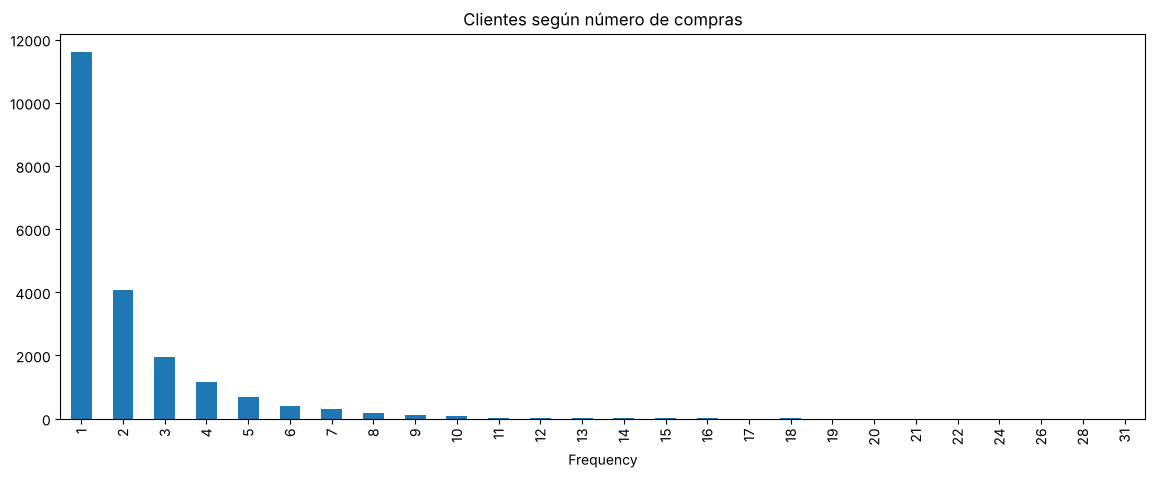

In [62]:
# Graficamos
rfm.Frequency.value_counts().sort_index().plot(kind='bar', figsize=(14, 5), title='Clientes según número de compras');

In [63]:
# Porcentaje de clientes que han hecho una sola compra
clientes_una_compra = rfm.Frequency[rfm.Frequency == 1].shape[0]
print('Clientes con una sola compra:', clientes_una_compra)
print(f'Porcentaje: {clientes_una_compra / total_clientes * 100:.2f} %')

Clientes con una sola compra: 11606
Porcentaje: 56.10 %


In [64]:
# Frecuencia media de compra entre los clientes
rfm.Frequency.mean()

np.float64(2.109628770301624)

In [65]:
# Clientes que han hecho 10 compras o más
# (Corrección: el comentario original decía "más de 10", pero el código usa >= 10)
rfm.Frequency[rfm.Frequency >= 10].shape[0]

253

In [66]:
# Porcentaje de clientes que han hecho más de 3 compras
clientes_mas_de_tres_compras = rfm.Frequency[rfm.Frequency > 3].shape[0]
(clientes_mas_de_tres_compras / total_clientes) * 100

14.767014694508894

In [67]:
# Los 10 clientes más leales (más compras)
rfm.sort_values('Frequency', ascending=False).head(10)

,Recency,Frequency
ID_Cliente,,
1703,8,31
15942,5,28
17446,32,26
12091,11,24
17757,16,22
15553,16,22
10569,8,22
16192,11,21
15294,34,21


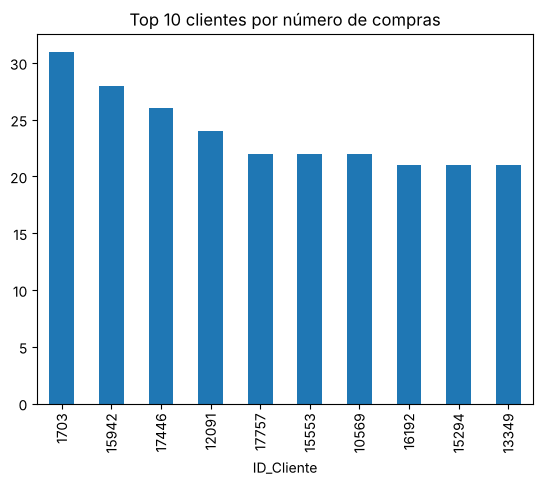

In [68]:
# Graficamos
rfm.sort_values('Frequency', ascending=False).head(10).plot(kind='bar', y='Frequency', legend=False,
                                                            title='Top 10 clientes por número de compras');

El 56 % de los clientes solo ha comprado **una vez**. Es el dato más importante del RFM: el negocio tiene un problema de **repetición**, no de captación.

### 3.3 Monetary

In [69]:
# Gasto total de cada cliente (Total_Venta ya existe desde el EDA, no hace falta recalcularla)
rfm['Monetary'] = productos.groupby('ID_Cliente')['Total_Venta'].sum()
rfm

,Recency,Frequency,Monetary
ID_Cliente,,,
1,344,1,65.16
2,195,2,68.31
3,364,1,24.60
4,52,2,139.85
5,179,5,143.81
...,...,...,...
22621,21,1,31.26
22622,15,1,18.21
22623,10,1,365.25


In [70]:
rfm.Monetary.describe()

count    20688.000000
mean       103.819227
std        107.361102
min          0.690000
25%         28.020000
50%         61.920000
75%        141.297500
max        500.000000
Name: Monetary, dtype: float64

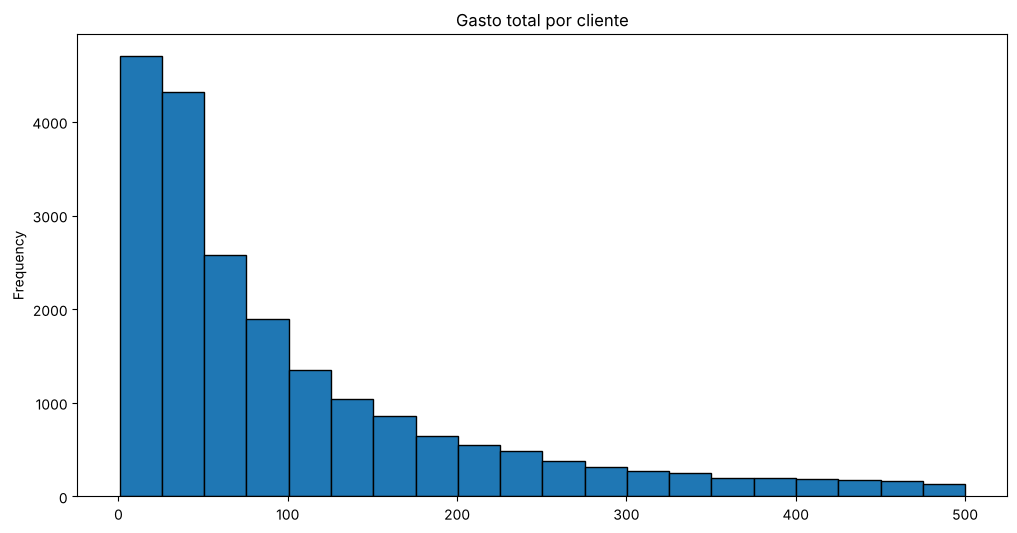

In [71]:
# Graficamos
rfm.Monetary.plot(kind='hist', bins=20, figsize=(12, 6), edgecolor='black', title='Gasto total por cliente');

In [72]:
# Gasto medio de los clientes
rfm.Monetary.mean()

np.float64(103.81922660479506)

In [73]:
# Clientes que más gastan
rfm.sort_values('Monetary', ascending=False).head(50)

,Recency,Frequency,Monetary
ID_Cliente,,,
628,297,1,500.00
7463,258,5,499.95
12807,53,2,499.92
11381,12,2,499.78
1552,305,5,499.68
10624,19,14,499.63
21580,2,5,499.62
13273,57,8,499.34
17779,30,12,499.27


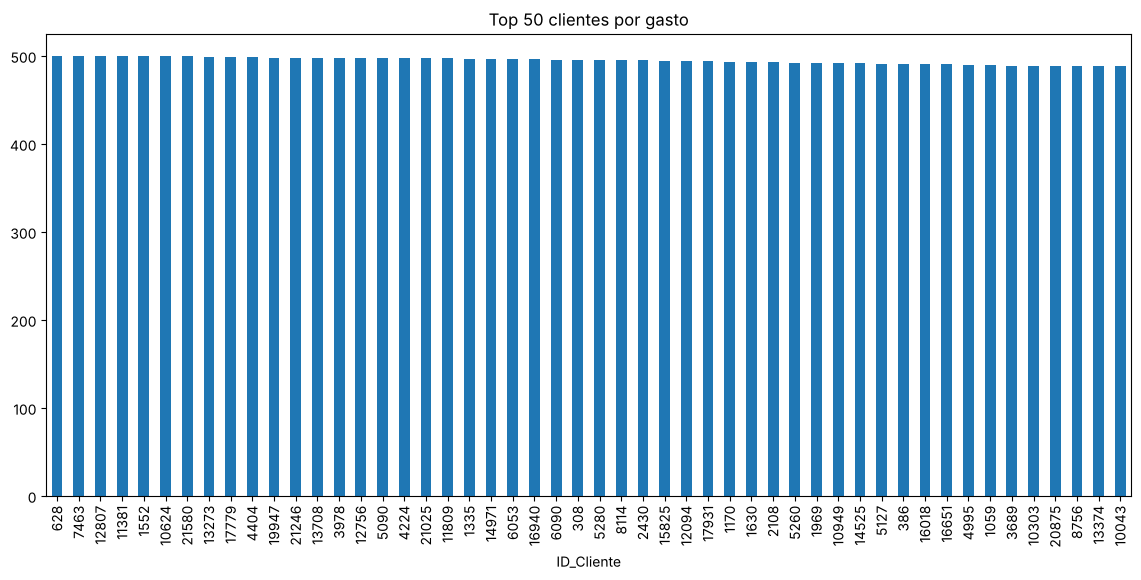

In [74]:
# Graficamos
rfm.sort_values('Monetary', ascending=False).head(50).plot(kind='bar', y='Monetary', figsize=(14, 6), legend=False,
                                                           title='Top 50 clientes por gasto');

**Observación:** el gasto máximo es **exactamente 500,00 €** y los 50 primeros están todos entre 490 y 500 €. En datos reales no habría un techo así. Es una señal de que el dataset es sintético o de que el gasto está **topado** en 500 €. No es un error del análisis, pero conviene saberlo antes de sacar conclusiones sobre los "mejores clientes".

**Pareto: ¿qué porcentaje de clientes genera el 80 % de los ingresos?**

In [75]:
# Ingreso total
ingreso_total = rfm['Monetary'].sum()

# Ordenamos de mayor a menor gasto y calculamos la suma acumulada
rfm_ord = rfm.sort_values('Monetary', ascending=False).copy()
rfm_ord['Monetary_acumulado'] = rfm_ord['Monetary'].cumsum()

# Clientes que, sumados desde el que más gasta, llegan al 80 % de los ingresos
clientes_80_ingreso = rfm_ord[rfm_ord['Monetary_acumulado'] <= 0.8 * ingreso_total]

print(f'Número de clientes que generan el 80 % de los ingresos: {len(clientes_80_ingreso)}')
print(f'Porcentaje sobre el total de clientes: {len(clientes_80_ingreso) / total_clientes * 100:.1f} %')
clientes_80_ingreso.head()

Número de clientes que generan el 80 % de los ingresos: 8624
Porcentaje sobre el total de clientes: 41.7 %


,Recency,Frequency,Monetary,Monetary_acumulado
ID_Cliente,,,,
628,297,1,500.00,500.00
7463,258,5,499.95,999.95
12807,53,2,499.92,1499.87
11381,12,2,499.78,1999.65
1552,305,5,499.68,2499.33


El 41,7 % de los clientes genera el 80 % de los ingresos. Está lejos del "20/80" clásico de Pareto: los ingresos están **bastante repartidos**, sin un pequeño grupo de clientes estrella.

**Mejora:** se ha añadido `.copy()` a `rfm_ord`. Sin él, añadir una columna a algo que sale de otra tabla puede dar un `SettingWithCopyWarning`. Aquí `sort_values` ya crea una tabla nueva, así que el resultado era correcto, pero `.copy()` deja claro que se trabaja sobre una copia.

### 3.4 Puntuaciones de 1 a 5

Se compara la forma de cortar cada métrica:

- `pd.qcut(serie, q=5)` corta por **cuantiles**: 5 grupos con el **mismo número de clientes**. Por eso las barras salen iguales (es su definición).
- `pd.cut(serie, bins=[...])` corta por **límites fijos** elegidos a mano. Los grupos tienen tamaños distintos, pero cada límite tiene un significado de negocio ("menos de 60 días", "más de 300 €").

Se eligió `pd.cut` con límites fijos, que es razonable porque los segmentos se entienden mejor.

**Asignación de puntuaciones (Recency)**

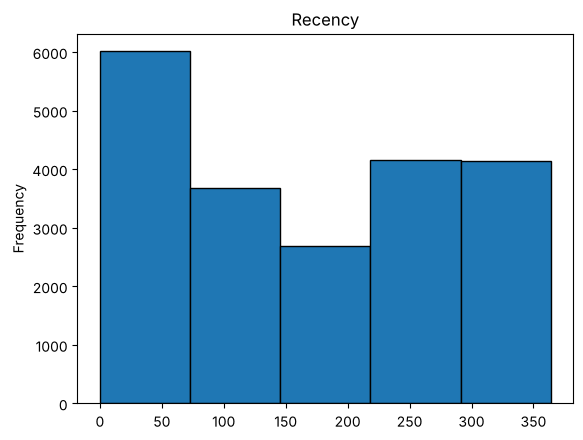

In [76]:
rfm.Recency.plot(kind='hist', bins=5, edgecolor='black', title='Recency');

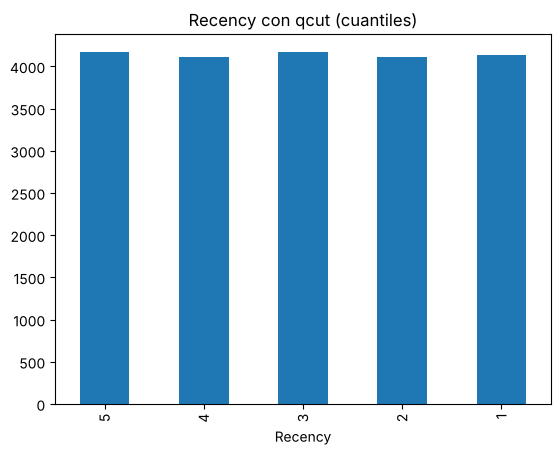

In [77]:
pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).value_counts(sort=False).plot(kind='bar', title='Recency con qcut (cuantiles)');

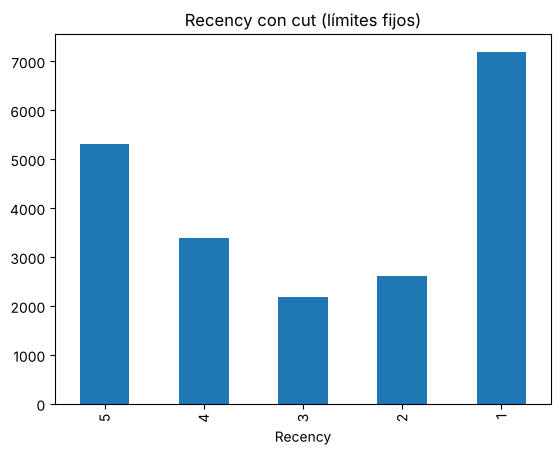

In [78]:
# Como qcut deja las barras iguales, aplicamos límites fijos
corte_prueba_r = pd.cut(rfm['Recency'], bins=[0, 60, 120, 180, 240, rfm['Recency'].max()],
                        labels=[5, 4, 3, 2, 1], include_lowest=True)
corte_prueba_r.value_counts(sort=False).plot(kind='bar', title='Recency con cut (límites fijos)');

Las etiquetas van **al revés** (`[5, 4, 3, 2, 1]`) porque en Recency menos días es mejor: 0-60 días recibe un 5.

`include_lowest=True` hace que el primer tramo incluya su límite inferior. Sin él, un cliente con Recency = 0 (compró el último día) se quedaría sin nota (`NaN`), porque los tramos de `pd.cut` son abiertos por la izquierda: `(0, 60]`.

**Asignación de puntuaciones (Frequency)**

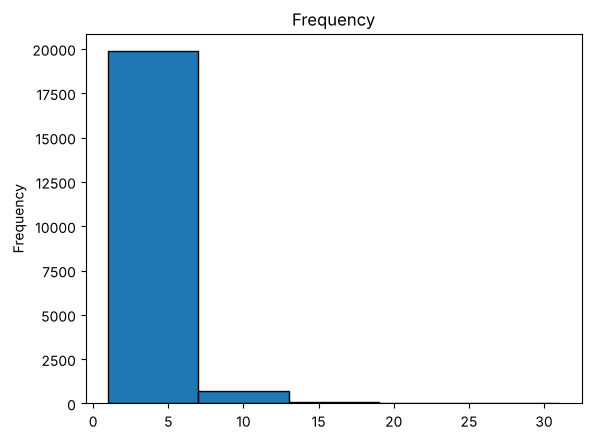

In [79]:
rfm.Frequency.plot(kind='hist', bins=5, edgecolor='black', title='Frequency');

In [80]:
rfm.Frequency.describe()

count    20688.000000
mean         2.109629
std          1.983245
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         31.000000
Name: Frequency, dtype: float64

In [81]:
# Mejora: por qué aquí no se puede usar qcut
try:
    pd.qcut(rfm['Frequency'], q=5, labels=[1, 2, 3, 4, 5])
except ValueError as error:
    print('qcut falla:', error)

qcut falla: Bin edges must be unique: Index([1.0, 1.0, 1.0, 2.0, 3.0, 31.0], dtype='float64', name='Frequency').
You can drop duplicate edges by setting the 'duplicates' kwarg


Con Frequency `qcut` ni siquiera funciona: más del 50 % de los clientes tiene exactamente 1 compra, así que varios cuantiles coinciden en el mismo valor y los límites se repiten. Es otra razón para usar límites fijos.

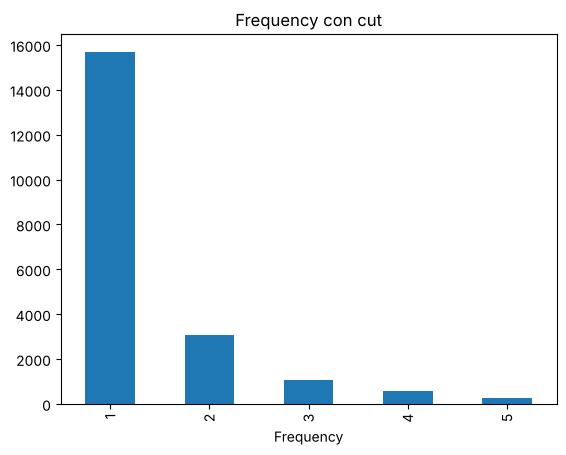

In [82]:
corte_prueba_f = pd.cut(rfm['Frequency'], bins=[1, 2, 4, 6, 9, rfm['Frequency'].max()],
                        labels=[1, 2, 3, 4, 5], include_lowest=True)
corte_prueba_f.value_counts(sort=False).plot(kind='bar', title='Frequency con cut');

**Corrección (error 5): qué hace realmente este corte.** Los límites `[1, 2, 4, 6, 9, 31]` generan estos tramos:

| Tramo | Compras | Nota f |
|---|---|---|
| [1, 2] | 1 o 2 | 1 |
| (2, 4] | 3 o 4 | 2 |
| (4, 6] | 5 o 6 | 3 |
| (6, 9] | 7, 8 o 9 | 4 |
| (9, 31] | 10 o más | 5 |

Quien compró **una vez** y quien compró **dos veces** reciben la misma nota, cuando la diferencia entre 1 y 2 compras (repetir o no) es justo la más importante en este negocio. Un corte como `[1, 1, 2, 4, 7, máx]` (1 / 2 / 3-4 / 5-7 / 8+) los separaría.

En este notebook **se mantiene el corte original**, porque es el que usa el dashboard de Tableau y cambiarlo cambiaría todos los segmentos. Pero hay que tenerlo en cuenta al leer los resultados.

**Asignación de puntuaciones (Monetary)**

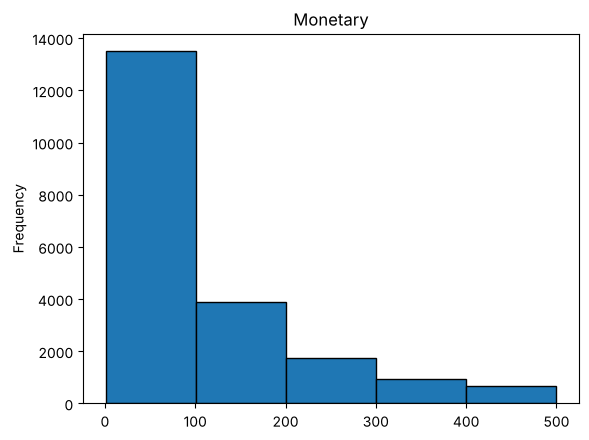

In [83]:
rfm.Monetary.plot(kind='hist', bins=5, edgecolor='black', title='Monetary');

In [84]:
rfm.Monetary.describe()

count    20688.000000
mean       103.819227
std        107.361102
min          0.690000
25%         28.020000
50%         61.920000
75%        141.297500
max        500.000000
Name: Monetary, dtype: float64

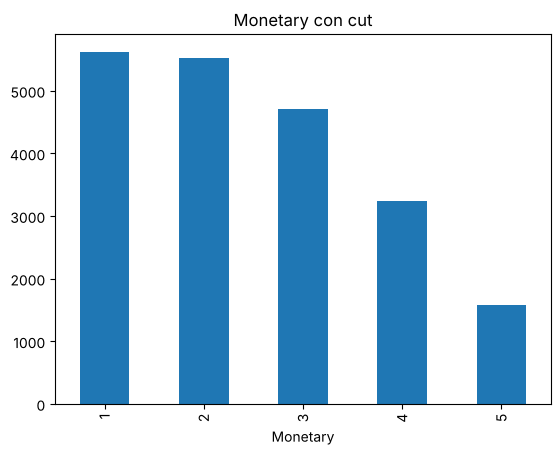

In [85]:
corte_prueba_m = pd.cut(rfm['Monetary'], bins=[0, 30, 70, 150, 300, rfm['Monetary'].max()],
                        labels=[1, 2, 3, 4, 5], include_lowest=True)
corte_prueba_m.value_counts(sort=False).plot(kind='bar', title='Monetary con cut');

### 3.5 Tabla RFM con puntuaciones

In [86]:
rfm['r'] = pd.cut(rfm['Recency'], bins=[0, 60, 120, 180, 240, rfm['Recency'].max()], labels=[5, 4, 3, 2, 1], include_lowest=True)
rfm['f'] = pd.cut(rfm['Frequency'], bins=[1, 2, 4, 6, 9, rfm['Frequency'].max()], labels=[1, 2, 3, 4, 5], include_lowest=True)
rfm['m'] = pd.cut(rfm['Monetary'], bins=[0, 30, 70, 150, 300, rfm['Monetary'].max()], labels=[1, 2, 3, 4, 5], include_lowest=True)

# Comprobación: ningún cliente se ha quedado sin nota
print('Clientes sin nota:', rfm[['r', 'f', 'm']].isna().sum().sum())
rfm.head()

Clientes sin nota: 0


,Recency,Frequency,Monetary,r,f,m
ID_Cliente,,,,,,
1,344,1,65.16,1,1,2
2,195,2,68.31,2,1,2
3,364,1,24.60,1,1,1
4,52,2,139.85,5,1,3
5,179,5,143.81,3,3,3


In [87]:
rfm.info()

<class 'pandas.DataFrame'>
Index: 20688 entries, 1 to 22625
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   Recency    20688 non-null  int64   
 1   Frequency  20688 non-null  int64   
 2   Monetary   20688 non-null  float64 
 3   r          20688 non-null  category
 4   f          20688 non-null  category
 5   m          20688 non-null  category
dtypes: category(3), float64(1), int64(2)
memory usage: 707.2 KB


`r`, `f` y `m` son de tipo `category` (es lo que devuelve `pd.cut`). Las categorías no se pueden sumar como números: `rfm['r'] + rfm['f']` da error. Por eso se convierten a texto y se **concatenan**: r = 5, f = 1, m = 3 da el código "513".

In [88]:
rfm['RFM'] = rfm['r'].astype(str) + rfm['f'].astype(str) + rfm['m'].astype(str)
rfm.head()

,Recency,Frequency,Monetary,r,f,m,RFM
ID_Cliente,,,,,,,
1,344,1,65.16,1,1,2,112
2,195,2,68.31,2,1,2,212
3,364,1,24.60,1,1,1,111
4,52,2,139.85,5,1,3,513
5,179,5,143.81,3,3,3,333


In [89]:
# Consulta sobre puntuaciones, por ejemplo para 111
rfm[rfm['RFM'] == '111']

,Recency,Frequency,Monetary,r,f,m,RFM
ID_Cliente,,,,,,,
3,364,1,24.60,1,1,1,111
11,337,1,12.70,1,1,1,111
15,357,1,11.46,1,1,1,111
18,346,1,7.60,1,1,1,111
22,351,1,13.50,1,1,1,111
...,...,...,...,...,...,...,...
21925,242,1,16.76,1,1,1,111
22127,253,1,12.56,1,1,1,111
22128,244,1,18.93,1,1,1,111


Hay 5 × 5 × 5 = 125 combinaciones posibles. No es operativo hacer una campaña para cada una, así que se agrupan en **segmentos con nombre**.

### 3.6 Segmentos personalizados

Cada nota se clasifica en **alta** (4-5), **media** (3) o **baja** (1-2), y se aplican las reglas en orden. La primera que se cumple decide el segmento:

In [90]:
def segmentar_clientes(fila):
    r, f, m = str(fila['r']), str(fila['f']), str(fila['m'])

    # Definir condiciones previamente para simplificar el código
    es_alto_r = r in ['4', '5']
    es_alto_f = f in ['4', '5']
    es_alto_m = m in ['4', '5']

    es_medio_r = r in ['3']
    es_medio_f = f in ['3']
    es_medio_m = m in ['3']

    es_bajo_r = r in ['1', '2']
    es_bajo_f = f in ['1', '2']
    es_bajo_m = m in ['1', '2']

    # Aplicar la lógica de los segmentos (la primera condición que se cumple gana)
    if es_alto_r and es_alto_f and es_alto_m:
        return 'Campeones'
    elif es_alto_r and es_alto_f and (es_alto_m or es_medio_m):
        return 'Clientes Leales'
    elif es_medio_r and es_alto_f and es_alto_m:
        return 'Clientes Rentables'
    elif es_bajo_r and es_medio_f and es_medio_m:
        return 'Leales Potenciales'
    elif es_bajo_r and es_bajo_f and es_alto_m:
        return 'Grandes Gastadores'
    elif es_alto_r and es_bajo_f and es_bajo_m:
        return 'Clientes Recientes'
    elif es_medio_r and es_medio_f and es_medio_m:
        return 'Prometedores'
    elif es_bajo_r and es_bajo_f and es_bajo_m:
        return 'En Riesgo'
    else:
        return 'Dudosos'

# Aplicar la función fila a fila (axis=1)
rfm['Segmento'] = rfm.apply(segmentar_clientes, axis=1)
rfm

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
1,344,1,65.16,1,1,2,112,En Riesgo
2,195,2,68.31,2,1,2,212,En Riesgo
3,364,1,24.60,1,1,1,111,En Riesgo
4,52,2,139.85,5,1,3,513,Dudosos
5,179,5,143.81,3,3,3,333,Prometedores
...,...,...,...,...,...,...,...,...
22621,21,1,31.26,5,1,2,512,Clientes Recientes
22622,15,1,18.21,5,1,1,511,Clientes Recientes
22623,10,1,365.25,5,1,5,515,Dudosos


Cómo funciona: `rfm.apply(funcion, axis=1)` llama a la función **una vez por fila** y le pasa esa fila. La función lee las tres notas y devuelve el nombre del segmento.

Dos detalles de la lógica:

- **"Clientes Leales" es en la práctica r alto, f alto y m medio.** Su condición incluye `es_alto_m`, pero ese caso (r alto, f alto, m alto) ya lo ha capturado "Campeones" en la línea anterior. No es un error, porque el resultado es correcto, pero la condición podría escribirse simplemente como `es_alto_r and es_alto_f and es_medio_m`.
- **`str(fila['r'])` depende del tipo de dato.** Funciona porque las etiquetas de `pd.cut` son enteros (`str(5)` da `'5'`). Si en algún momento la columna pasara a decimal (`5.0`), `str` daría `'5.0'`, no coincidiría con ninguna lista y **todos** los clientes caerían en "Dudosos". Es una forma frágil de comparar; sería más robusto usar `int(fila['r']) >= 4`.

**Consultas sobre RFM**

In [91]:
# Distribución de los segmentos (número de clientes)
segmentos = rfm['Segmento'].value_counts()
pd.DataFrame({'clientes': segmentos, '%': (segmentos / segmentos.sum() * 100).round(1)})

,clientes,%
Segmento,,
Dudosos,8621,41.7
En Riesgo,5951,28.8
Clientes Recientes,3933,19.0
Grandes Gastadores,1409,6.8
Campeones,582,2.8
Clientes Leales,67,0.3
Leales Potenciales,65,0.3
Clientes Rentables,39,0.2
Prometedores,21,0.1


**Corrección (error 5): ¿quién está en "Dudosos"?** Es el segmento más grande, con el 42 % de los clientes, y se define por exclusión: es todo lo que no cumple ninguna regla. Se desglosa por su código RFM:

In [92]:
dudosos = rfm[rfm['Segmento'] == 'Dudosos']
print('Clientes Dudosos:', len(dudosos))
print('\nDudosos según su nota de recencia r (5 = compró hace poco):')
print(dudosos['r'].value_counts(sort=False))
print('\nCódigos RFM más frecuentes dentro de Dudosos:')
print(dudosos['RFM'].value_counts().head(10))

Clientes Dudosos: 8621

Dudosos según su nota de recencia r (5 = compró hace poco):
r
5    2648
4    1481
3    2116
2     645
1    1731
Name: count, dtype: int64

Códigos RFM más frecuentes dentro de Dudosos:
RFM
113    1143
513     738
311     600
312     574
413     557
213     480
524     418
523     409
313     349
514     323
Name: count, dtype: int64


"Dudosos" no es un grupo homogéneo. Mezcla, por ejemplo, clientes **r = 5, f = 1, m = 3** (compraron hace menos de 2 meses y gastaron 70-150 €: muy buenos candidatos a repetir) con clientes **r = 1, f = 1, m = 3** (compraron hace casi un año). Casi todos tienen alguna nota **media** (m = 3 o r = 3) combinada con notas altas o bajas en las demás, y por eso no encajan: las reglas solo contemplan el valor medio en combinaciones muy concretas ("Clientes Leales", "Leales Potenciales" y "Prometedores", que además exigen f = 3 o más).

Tratarlos a todos como "inactivos", como hace la campaña de reactivación de más abajo, es un error de negocio: a un cliente que compró hace 20 días no se le manda una campaña de "te echamos de menos".

In [93]:
# Cliente promedio
rfm[['Recency', 'Frequency', 'Monetary']].mean()

Recency      168.527020
Frequency      2.109629
Monetary     103.819227
dtype: float64

In [94]:
# Cliente que está en la mediana
rfm[['Recency', 'Frequency', 'Monetary']].median()

Recency      166.00
Frequency      1.00
Monetary      61.92
dtype: float64

La media y la mediana de Frequency y Monetary difieren mucho (2,1 frente a 1 compra; 103,8 € frente a 61,9 €). Las dos variables son muy asimétricas, y el cliente "típico" se describe mejor con la mediana: **1 compra de unos 62 €**.

In [95]:
# Total de ventas, venta media y peso sobre el total por segmento
total_monetary = rfm['Monetary'].sum()
resumen_segmentos = rfm.groupby('Segmento').agg(
    clientes=('Monetary', 'size'),
    ventas_totales=('Monetary', 'sum'),
    venta_media=('Monetary', 'mean'),
)
resumen_segmentos['%_ingresos'] = resumen_segmentos['ventas_totales'] / total_monetary * 100
resumen_segmentos.sort_values('ventas_totales', ascending=False).round(2)

,clientes,ventas_totales,venta_media,%_ingresos
Segmento,,,,
Dudosos,8621,1247011.72,144.65,58.06
Grandes Gastadores,1409,358809.03,254.66,16.71
Campeones,582,193377.01,332.26,9.00
En Riesgo,5951,184709.84,31.04,8.60
Clientes Recientes,3933,133473.22,33.94,6.21
Clientes Rentables,39,12695.43,325.52,0.59
Clientes Leales,67,7802.28,116.45,0.36
Leales Potenciales,65,7470.30,114.93,0.35
Prometedores,21,2463.33,117.30,0.11


En el original eran tres consultas separadas (suma, media y porcentaje por segmento). Aquí se juntan en una tabla con `agg`, y los valores son los mismos. "Dudosos" genera el 58 % de los ingresos: otra razón para no despreciarlo como "inactivo".

### 3.7 Treemaps

`squarify` dibuja un **treemap**: cada rectángulo tiene un área proporcional a su valor.

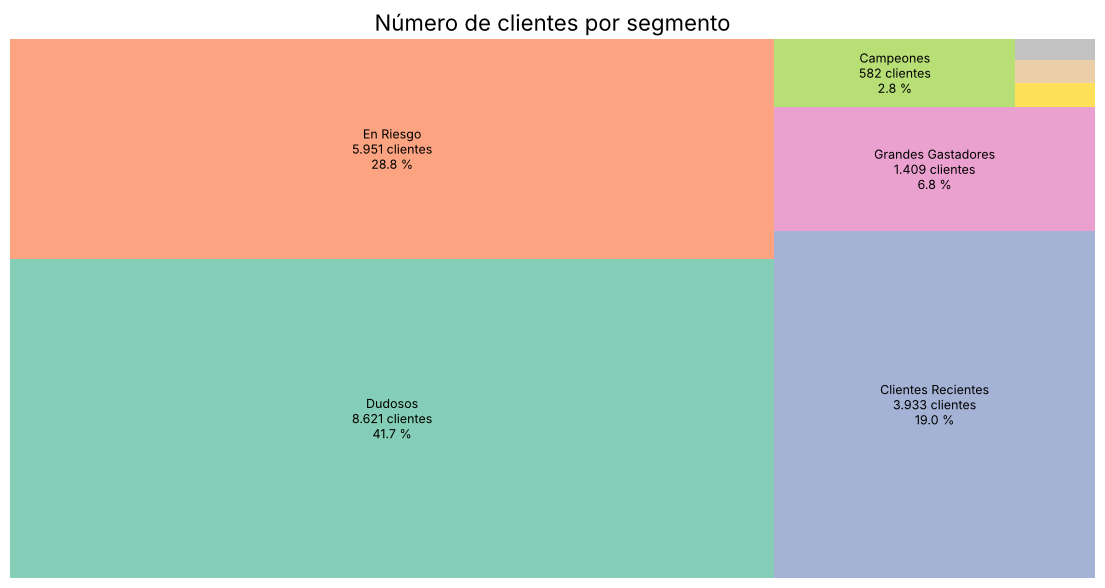

In [96]:
def treemap(serie, titulo, formato):
    # Treemap con el nombre, el valor y el % de cada segmento
    serie = serie.sort_values(ascending=False)
    # Los segmentos de menos del 2 % no llevan etiqueta: no caben (sus cifras están en la tabla de resumen)
    etiquetas = [f'{nombre}\n{formato(valor)}\n{valor / serie.sum() * 100:.1f} %' if valor / serie.sum() >= 0.02 else ''
                 for nombre, valor in serie.items()]
    colores = plt.cm.Set2(range(len(serie)))
    plt.figure(figsize=(14, 7))
    squarify.plot(sizes=serie.values, label=etiquetas, color=colores, alpha=0.8,
                  text_kwargs={'fontsize': 9})
    plt.title(titulo, fontsize=16)
    plt.axis('off')
    plt.show()

# Número de clientes por segmento
treemap(rfm['Segmento'].value_counts(), 'Número de clientes por segmento', lambda v: f'{v:,.0f} clientes'.replace(',', '.'))

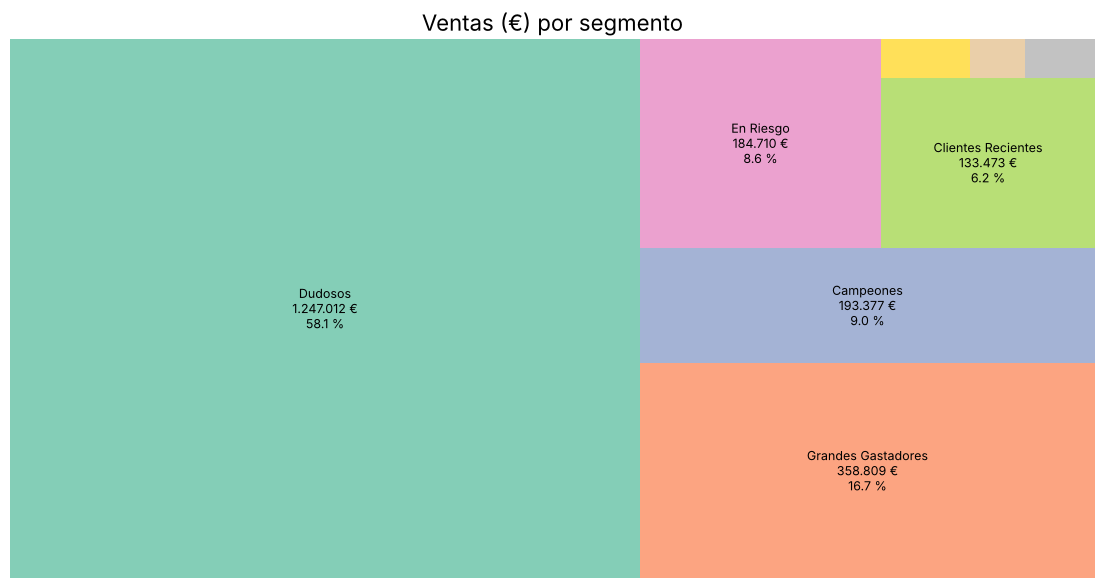

In [97]:
# Ventas (€) por segmento
treemap(rfm.groupby('Segmento')['Monetary'].sum(), 'Ventas (€) por segmento', lambda v: f'{v:,.0f} €'.replace(',', '.'))

**Corrección:** el segundo treemap se titulaba "Número de Ventas por Segmento", pero lo que mide es el **importe** vendido (suma de `Monetary`), no el número de ventas. Además, ahora cada rectángulo muestra su valor y su porcentaje, porque sin cifras no se pueden comparar. Los segmentos con menos del 2 % no llevan etiqueta porque el texto no cabe y se superpone; sus cifras están en la tabla de resumen de 3.6.

### 3.8 Propuesta de acción de marketing

**1. Campaña de Reactivación:** dirigida a clientes inactivos o en riesgo, ofreciéndoles incentivos para volver a comprar.
* En Riesgo: clientes con baja recencia, frecuencia y valor monetario. Probablemente han dejado de comprar por completo.
* Dudosos: clientes que no han mostrado un patrón consistente; es probable que estén inactivos o a punto de perderse.

**2. Campaña de Conversión de Compradores Únicos:** motivar a los clientes que han comprado solo una vez a convertirse en recurrentes mediante ofertas y seguimiento personalizado.
* Clientes Recientes: compraron por primera vez recientemente, pero no han repetido compra.
* Prometedores: clientes con valores medios en todas las métricas. Han mostrado interés, pero aún no han demostrado lealtad o valor alto.
* Clientes Rentables: compran con frecuencia y gastan bien, pero podrían no haber comprado recientemente.

**3. Campaña de Upselling/Cross-selling:** aumentar el valor medio de compra mediante paquetes, productos premium y descuentos por gasto mínimo.
* Clientes Rentables: compran con frecuencia y gastan bastante, pero pueden no estar comprando productos de mayor valor.
* Leales Potenciales: han sido consistentes, pero con un valor monetario moderado. Pueden ser incentivados a gastar más.
* Grandes Gastadores: compran de forma esporádica, pero cuando lo hacen, gastan mucho. Podrían comprar con mayor frecuencia o añadir más productos al carrito.

**1. Campaña de Reactivación**

In [98]:
segmentos_reactivacion = ['En Riesgo', 'Dudosos']
clientes_reactivacion = rfm[rfm['Segmento'].isin(segmentos_reactivacion)]
clientes_reactivacion

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
1,344,1,65.16,1,1,2,112,En Riesgo
2,195,2,68.31,2,1,2,212,En Riesgo
3,364,1,24.60,1,1,1,111,En Riesgo
4,52,2,139.85,5,1,3,513,Dudosos
6,275,1,91.66,1,1,3,113,Dudosos
...,...,...,...,...,...,...,...,...
22617,19,1,84.48,5,1,3,513,Dudosos
22618,164,1,9.54,3,1,1,311,Dudosos
22623,10,1,365.25,5,1,5,515,Dudosos


En el original esta tabla se llamaba `clientes_inactivos`, el mismo nombre que ya se había usado en 3.1 para un **número** (los clientes con 180 días o más sin comprar). Reutilizar un nombre para otra cosa es una fuente típica de errores al reejecutar celdas sueltas, así que aquí se llama `clientes_reactivacion`.

**2. Campaña de Conversión de Compradores Únicos**

In [99]:
segmentos_conversion = ['Clientes Recientes', 'Prometedores', 'Clientes Rentables']
clientes_conversion = rfm[rfm['Segmento'].isin(segmentos_conversion)]
clientes_conversion

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
5,179,5,143.81,3,3,3,333,Prometedores
7,87,1,53.52,4,1,2,412,Clientes Recientes
23,101,1,5.52,4,1,1,411,Clientes Recientes
84,134,6,82.80,3,3,3,333,Prometedores
108,93,2,43.16,4,1,2,412,Clientes Recientes
...,...,...,...,...,...,...,...,...
22616,66,1,12.06,4,1,1,411,Clientes Recientes
22619,27,1,18.54,5,1,1,511,Clientes Recientes
22620,60,1,43.00,5,1,2,512,Clientes Recientes


**3. Campaña de Upselling/Cross-selling**

In [100]:
segmentos_upselling = ['Clientes Rentables', 'Leales Potenciales', 'Grandes Gastadores']
clientes_upselling = rfm[rfm['Segmento'].isin(segmentos_upselling)]
clientes_upselling

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
10,323,1,220.62,1,1,4,114,Grandes Gastadores
13,324,2,159.72,1,1,4,114,Grandes Gastadores
14,311,3,402.42,1,2,5,125,Grandes Gastadores
16,257,2,310.80,1,1,5,115,Grandes Gastadores
19,262,1,199.90,1,1,4,114,Grandes Gastadores
...,...,...,...,...,...,...,...,...
21804,187,1,213.91,2,1,4,214,Grandes Gastadores
21883,198,1,159.12,2,1,4,214,Grandes Gastadores
21958,227,1,158.85,2,1,4,214,Grandes Gastadores


**Corrección (error 6): las campañas se solapan y algunas no encajan con su público.**

In [101]:
print('Clientes en la campaña de reactivación:', len(clientes_reactivacion))
print('  de ellos, Dudosos que compraron en los últimos 60 días (r = 5):',
      ((clientes_reactivacion['Segmento'] == 'Dudosos') & (clientes_reactivacion['r'] == 5)).sum())
print('Clientes que reciben conversión Y upselling:',
      len(clientes_conversion.index.intersection(clientes_upselling.index)))
print('Compradores únicos (Frequency = 1) dentro de la campaña de conversión:',
      (clientes_conversion['Frequency'] == 1).sum(), 'de', len(clientes_conversion))

Clientes en la campaña de reactivación: 14572
  de ellos, Dudosos que compraron en los últimos 60 días (r = 5): 2648
Clientes que reciben conversión Y upselling: 39
Compradores únicos (Frequency = 1) dentro de la campaña de conversión: 2931 de 3993


- **"Clientes Rentables" recibe dos campañas** (conversión y upselling): esos 39 clientes recibirían mensajes contradictorios. Además, tienen f alto (7 compras o más), así que no son "compradores únicos". Encajan solo en upselling.
- **"Prometedores"** tienen f = 3 (5-6 compras): tampoco son compradores únicos.
- **Dudosos con r = 5** compraron hace menos de 60 días: no necesitan reactivación, sino un empujón para la segunda compra (campaña de conversión).

**Código RFM unificado**

```python
fecha_max = productos['Fecha'].max()
rfm = productos.groupby('ID_Cliente').agg(Recency=('Fecha', lambda x: (fecha_max - x.max()).days))
rfm['Frequency'] = productos.groupby('ID_Cliente')['ID_Transaccion'].nunique()
rfm['Monetary'] = productos.groupby('ID_Cliente')['Total_Venta'].sum()

rfm['r'] = pd.cut(rfm['Recency'], bins=[0, 60, 120, 180, 240, rfm['Recency'].max()], labels=[5, 4, 3, 2, 1], include_lowest=True)
rfm['f'] = pd.cut(rfm['Frequency'], bins=[1, 2, 4, 6, 9, rfm['Frequency'].max()], labels=[1, 2, 3, 4, 5], include_lowest=True)
rfm['m'] = pd.cut(rfm['Monetary'], bins=[0, 30, 70, 150, 300, rfm['Monetary'].max()], labels=[1, 2, 3, 4, 5], include_lowest=True)
rfm['RFM'] = rfm['r'].astype(str) + rfm['f'].astype(str) + rfm['m'].astype(str)
rfm['Segmento'] = rfm.apply(segmentar_clientes, axis=1)
```

## 4. Análisis de cohortes (`03_Cohortes`)

Una **cohorte** es el grupo de clientes que hizo su **primera compra en el mismo mes**. Seguir a cada cohorte mes a mes permite ver cuántos de esos clientes vuelven a comprar: su **retención**.

Ejemplo: de los 3.114 clientes que compraron por primera vez en enero, ¿cuántos compraron también en febrero, en marzo...?

### 4.1 Mes de cada transacción

In [102]:
# Columna con el mes y el año de cada transacción
productos['MesTransaccion'] = productos['Fecha'].dt.to_period('M')

productos[['ID_Cliente', 'Fecha', 'MesTransaccion']]

,ID_Cliente,Fecha,MesTransaccion
0,1,2023-01-21,2023-01
1,1,2023-01-21,2023-01
2,2,2023-03-24,2023-03
3,2,2023-06-19,2023-06
4,3,2023-01-01,2023-01
...,...,...,...
78261,7139,2023-11-30,2023-11
78262,3056,2023-10-17,2023-10
78263,12790,2023-06-04,2023-06
78264,5624,2023-10-03,2023-10


`.dt.to_period('M')` convierte una fecha en un **periodo mensual**: 2023-01-21 pasa a 2023-01. Así todas las compras de un mismo mes quedan agrupadas.

In [103]:
# Revisamos que tenemos el mismo número de clientes
productos.ID_Cliente.nunique()

20688

In [104]:
# Vista ordenada de los datos por Cliente y MesTransaccion
productos.sort_values(by=['ID_Cliente', 'MesTransaccion']).head(20)

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,Margen,MesTransaccion
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,11.44,2023-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,4.88,2023-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,9.51,2023-03
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,17.88,2023-06
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2.84,2023-01
5,3,2023-01-01,90,TW8,WHV3G,1.15,3.0,1.38,4.14,0.69,2023-01
6,3,2023-01-01,90,TW8,WALAE,0.89,3.0,1.38,4.14,1.47,2023-01
7,4,2023-07-11,34042,69B,APEJQ,3.48,5.0,6.69,33.45,16.05,2023-07
8,4,2023-11-09,54618,YMJ,QR49F,5.31,4.0,7.37,29.48,8.24,2023-11
9,4,2023-11-09,54618,29A,RBNO8,5.67,4.0,8.65,34.60,11.92,2023-11


### 4.2 Mes de cohorte

El mes de cohorte de un cliente es el mes de su **primera** compra, es decir, el mínimo de sus `MesTransaccion`.

In [105]:
# Con agg: una fila por cliente (reduce la tabla)
productos.groupby('ID_Cliente')['MesTransaccion'].agg('min')

ID_Cliente
1        2023-01
2        2023-03
3        2023-01
4        2023-07
5        2023-02
          ...   
22621    2023-12
22622    2023-12
22623    2023-12
22624    2023-12
22625    2023-12
Name: MesTransaccion, Length: 20688, dtype: period[M]

In [106]:
# Con transform: el mismo valor, pero repetido en cada fila del cliente (mantiene el tamaño de la tabla)
productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')

0        2023-01
1        2023-01
2        2023-03
3        2023-03
4        2023-01
          ...   
78261    2023-11
78262    2023-10
78263    2023-06
78264    2023-10
78265    2023-08
Name: MesTransaccion, Length: 78266, dtype: period[M]

La diferencia entre `agg` y `transform` es clave:

- `agg('min')` devuelve **una fila por cliente** (20.688 filas).
- `transform('min')` devuelve **una fila por cada fila original** (78.266), con el mínimo de su cliente repetido. Por eso se puede asignar directamente como columna nueva.

In [107]:
productos['MesCohorte'] = productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')
productos.sort_values(by=['ID_Cliente', 'MesTransaccion']).head(20)

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,Margen,MesTransaccion,MesCohorte
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,11.44,2023-01,2023-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,4.88,2023-01,2023-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,9.51,2023-03,2023-03
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,17.88,2023-06,2023-03
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2.84,2023-01,2023-01
5,3,2023-01-01,90,TW8,WHV3G,1.15,3.0,1.38,4.14,0.69,2023-01,2023-01
6,3,2023-01-01,90,TW8,WALAE,0.89,3.0,1.38,4.14,1.47,2023-01,2023-01
7,4,2023-07-11,34042,69B,APEJQ,3.48,5.0,6.69,33.45,16.05,2023-07,2023-07
8,4,2023-11-09,54618,YMJ,QR49F,5.31,4.0,7.37,29.48,8.24,2023-11,2023-07
9,4,2023-11-09,54618,29A,RBNO8,5.67,4.0,8.65,34.60,11.92,2023-11,2023-07


### 4.3 Eliminar las cohortes que no están completas

Se estudian **6 meses** de vida de cada cohorte. Los datos acaban en diciembre de 2023, así que la cohorte de **julio** es la última que tiene 6 meses completos (julio a diciembre). Las cohortes de agosto en adelante se eliminan.

In [108]:
resultados = productos[productos['MesCohorte'] <= '2023-07'].copy()
resultados.info()

<class 'pandas.DataFrame'>
Index: 61497 entries, 0 to 78263
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          61497 non-null  int64         
 1   Fecha               61497 non-null  datetime64[us]
 2   ID_Transaccion      61497 non-null  int64         
 3   Categoria_Producto  61497 non-null  str           
 4   Producto            61497 non-null  str           
 5   Coste_Unitario      61497 non-null  float64       
 6   Cantidad            61497 non-null  float64       
 7   Precio_Unitario     61497 non-null  float64       
 8   Total_Venta         61497 non-null  float64       
 9   Margen              61497 non-null  float64       
 10  MesTransaccion      61497 non-null  period[M]     
 11  MesCohorte          61497 non-null  period[M]     
dtypes: datetime64[us](1), float64(5), int64(2), period[M](2), str(2)
memory usage: 6.1 MB


`MesCohorte <= '2023-07'` funciona porque pandas sabe comparar un `Period` con un texto que representa un periodo.

**Mejora:** el `.copy()` se pone aquí directamente. Así `resultados` es una tabla independiente y no una "vista" de `productos`, lo que evita el `SettingWithCopyWarning` al añadir columnas. En el original se hacía en una celda aparte.

**Aviso sobre la cohorte de enero (censura por la izquierda).** Los datos **empiezan** el 1 de enero de 2023. Un cliente que ya compraba en 2022 y compra en enero aparece como "cliente nuevo de enero", aunque no lo sea. Eso explica que la cohorte de enero tenga una retención mucho mayor que las demás (32,5 % en M2 frente a 13-20 %): probablemente lleva dentro clientes antiguos y fieles. Hay que leer esa cohorte con cautela.

### 4.4 Quedarse solo con los 6 primeros meses de cada cohorte

El original convertía `MesTransaccion` y `MesCohorte` a `datetime` y sumaba `pd.DateOffset(months=5)`. Funciona, pero hay una forma más directa: restar dos periodos mensuales da el **número de meses** entre ellos. Con eso se calcula a la vez el filtro y la columna `MesCliente` (M1 = mes de la primera compra, M2 = el mes siguiente...).

In [109]:
# Meses transcurridos desde la primera compra (0 = el mismo mes de la cohorte)
meses_desde_cohorte = (resultados['MesTransaccion'] - resultados['MesCohorte']).apply(lambda x: x.n)

# Nos quedamos solo con los 6 primeros meses de vida (0 a 5)
resultados_filtrados = resultados[meses_desde_cohorte <= 5].copy()

# MesCliente: 'M1' ... 'M6'
resultados_filtrados['MesCliente'] = 'M' + (meses_desde_cohorte[meses_desde_cohorte <= 5] + 1).astype(str)

# Pasamos los meses a fecha (primer día del mes), como en el original, para Tableau y para los gráficos
resultados_filtrados['MesTransaccion'] = resultados_filtrados['MesTransaccion'].dt.to_timestamp()
resultados_filtrados['MesCohorte'] = resultados_filtrados['MesCohorte'].dt.to_timestamp()

resultados_filtrados.info()

<class 'pandas.DataFrame'>
Index: 54405 entries, 0 to 78263
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          54405 non-null  int64         
 1   Fecha               54405 non-null  datetime64[us]
 2   ID_Transaccion      54405 non-null  int64         
 3   Categoria_Producto  54405 non-null  str           
 4   Producto            54405 non-null  str           
 5   Coste_Unitario      54405 non-null  float64       
 6   Cantidad            54405 non-null  float64       
 7   Precio_Unitario     54405 non-null  float64       
 8   Total_Venta         54405 non-null  float64       
 9   Margen              54405 non-null  float64       
 10  MesTransaccion      54405 non-null  datetime64[us]
 11  MesCohorte          54405 non-null  datetime64[us]
 12  MesCliente          54405 non-null  str           
dtypes: datetime64[us](3), float64(5), int64(2), str(3)
memory usag

Cómo funciona:

1. `MesTransaccion - MesCohorte` entre dos `Period` da un objeto `MonthEnd` con un atributo `.n`, que es el número de meses (de enero a marzo, `.n` = 2).
2. Se filtran las filas con 5 meses o menos de diferencia.
3. `MesCliente` es "M" + (meses + 1): enero → enero es M1, enero → marzo es M3.
4. `.dt.to_timestamp()` pasa el periodo a fecha (2023-01 pasa a 2023-01-01), el mismo resultado que el `pd.to_datetime(... .astype(str), format='%Y-%m')` del original.

El resultado es idéntico al original: **54.405 líneas** de **14.367 clientes**. Este es el dataset base de cohortes y LTV.

In [110]:
print('Líneas:', len(resultados_filtrados))
print('Clientes:', resultados_filtrados['ID_Cliente'].nunique())
resultados_filtrados[['ID_Cliente', 'Fecha', 'MesTransaccion', 'MesCohorte', 'MesCliente']].head(10)

Líneas: 54405
Clientes: 14367


,ID_Cliente,Fecha,MesTransaccion,MesCohorte,MesCliente
0,1,2023-01-21,2023-01-01,2023-01-01,M1
1,1,2023-01-21,2023-01-01,2023-01-01,M1
2,2,2023-03-24,2023-03-01,2023-03-01,M1
3,2,2023-06-19,2023-06-01,2023-03-01,M4
4,3,2023-01-01,2023-01-01,2023-01-01,M1
5,3,2023-01-01,2023-01-01,2023-01-01,M1
6,3,2023-01-01,2023-01-01,2023-01-01,M1
7,4,2023-07-11,2023-07-01,2023-07-01,M1
8,4,2023-11-09,2023-11-01,2023-07-01,M5
9,4,2023-11-09,2023-11-01,2023-07-01,M5


### 4.5 Tabla de cohortes por meses naturales

In [111]:
cohorte_final_natural = pd.pivot_table(
    resultados_filtrados,
    index='MesCohorte',
    columns='MesTransaccion',
    values='ID_Cliente',
    aggfunc='nunique',          # clientes únicos por cohorte y mes
).fillna(0).astype(int)         # los huecos (meses anteriores a la cohorte o fuera de la ventana) son 0

cohorte_final_natural.index = cohorte_final_natural.index.strftime('%Y-%m')
cohorte_final_natural.columns = cohorte_final_natural.columns.strftime('%Y-%m')
cohorte_final_natural

MesTransaccion,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
MesCohorte,,,,,,,,,,,,
2023-01,3114,1011,778,458,189,134,0,0,0,0,0,0
2023-02,0,2051,408,241,121,72,53,0,0,0,0,0
2023-03,0,0,2160,390,303,261,206,213,0,0,0,0
2023-04,0,0,0,2079,403,329,265,295,281,0,0,0
2023-05,0,0,0,0,2334,434,380,311,373,361,0,0
2023-06,0,0,0,0,0,1461,210,203,212,206,205,0
2023-07,0,0,0,0,0,0,1168,147,156,162,154,170


Cada fila es una cohorte y cada columna un mes **del calendario**. La tabla forma una "escalera", porque cada cohorte empieza un mes más tarde. Así es difícil comparar cohortes entre sí. Por eso se pasa a meses **de vida del cliente** (M1...M6).

**Mejora:** las fechas del índice y de las columnas se muestran como `2023-01` en lugar de `2023-01-01 00:00:00`, que es más legible.

### 4.6 Tabla de cohortes por mes de vida del cliente

In [112]:
tabla_cohortes = pd.pivot_table(
    resultados_filtrados,
    index='MesCohorte',
    columns='MesCliente',
    values='ID_Cliente',
    aggfunc='nunique',
).fillna(0).astype(int)

tabla_cohortes.index = tabla_cohortes.index.strftime('%Y-%m')
tabla_cohortes

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01,3114,1011,778,458,189,134
2023-02,2051,408,241,121,72,53
2023-03,2160,390,303,261,206,213
2023-04,2079,403,329,265,295,281
2023-05,2334,434,380,311,373,361
2023-06,1461,210,203,212,206,205
2023-07,1168,147,156,162,154,170


In [113]:
# Tabla de cohortes formateada (más azul = más clientes)
tabla_cohortes.style.background_gradient(cmap='Blues', axis=None)

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01,3114,1011,778,458,189,134
2023-02,2051,408,241,121,72,53
2023-03,2160,390,303,261,206,213
2023-04,2079,403,329,265,295,281
2023-05,2334,434,380,311,373,361
2023-06,1461,210,203,212,206,205
2023-07,1168,147,156,162,154,170


### 4.7 Tasa de retención

Retención del mes k = clientes activos en Mk / clientes de la cohorte en M1 × 100.

In [114]:
# Retención sin redondear (es la que se usa en los cálculos del LTV)
tabla_retencion_exacta = tabla_cohortes.div(tabla_cohortes['M1'], axis=0) * 100

# Versión redondeada, solo para mostrar
tabla_retencion = tabla_retencion_exacta.round(1)
tabla_retencion

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01,100.0,32.5,25.0,14.7,6.1,4.3
2023-02,100.0,19.9,11.8,5.9,3.5,2.6
2023-03,100.0,18.1,14.0,12.1,9.5,9.9
2023-04,100.0,19.4,15.8,12.7,14.2,13.5
2023-05,100.0,18.6,16.3,13.3,16.0,15.5
2023-06,100.0,14.4,13.9,14.5,14.1,14.0
2023-07,100.0,12.6,13.4,13.9,13.2,14.6


In [115]:
# Aplicamos formato
tabla_retencion.style.format('{:.1f}').background_gradient(cmap='Blues', axis=None)

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01,100.0,32.5,25.0,14.7,6.1,4.3
2023-02,100.0,19.9,11.8,5.9,3.5,2.6
2023-03,100.0,18.1,14.0,12.1,9.5,9.9
2023-04,100.0,19.4,15.8,12.7,14.2,13.5
2023-05,100.0,18.6,16.3,13.3,16.0,15.5
2023-06,100.0,14.4,13.9,14.5,14.1,14.0
2023-07,100.0,12.6,13.4,13.9,13.2,14.6


`div(..., axis=0)` divide **cada fila** entre su propio valor de M1 (`axis=0` alinea por filas). Sin `axis=0` intentaría alinear las columnas y el resultado no tendría sentido.

**Mejora:** se guardan dos versiones: `tabla_retencion_exacta` para los cálculos y `tabla_retencion` (redondeada) para mostrar. El original redondeaba la tabla y luego la usaba para el LTV, lo que añade pequeños errores (ver error 7).

**Consultas con la tabla de retención**

In [116]:
# Media SIMPLE de la retención de las cohortes (incorrecta)
tabla_retencion_exacta.mean()

MesCliente
M1    100.000000
M2     19.336130
M3     15.731260
M4     12.448916
M5     10.938916
M6     10.616824
dtype: float64

(El original daba 19,36 % en M2, 15,74 % en M3... porque promediaba los porcentajes ya redondeados; la diferencia es mínima.)

No es correcta: promedia porcentajes de cohortes de tamaños muy distintos sin tener en cuenta su tamaño. La cohorte de julio (1.168 clientes) pesa lo mismo que la de enero (3.114).

Hay que calcular la retención media **ponderada**, desde la tabla de valores absolutos: total de clientes activos en Mk de todas las cohortes / total de clientes en M1.

In [117]:
# Total de clientes en M1 de todas las cohortes
total_inicial = tabla_cohortes['M1'].sum()

# Total de clientes activos en cada mes
total_retenidos = tabla_cohortes.sum()

# Retención media ponderada
tasa_media = total_retenidos / total_inicial
tasa_media

MesCliente
M1    1.000000
M2    0.209021
M3    0.166353
M4    0.124591
M5    0.104058
M6    0.098629
dtype: float64

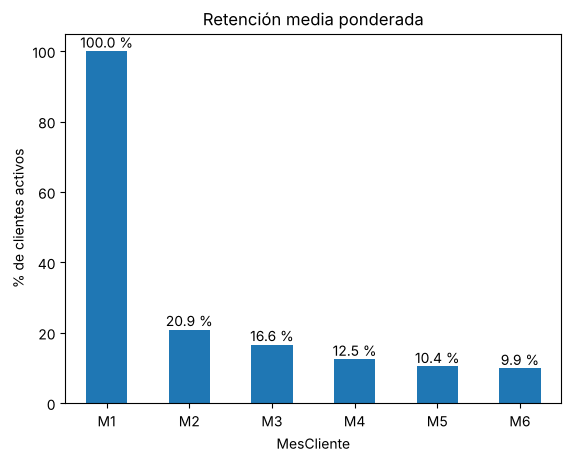

In [118]:
ax = (tasa_media * 100).plot(kind='bar', title='Retención media ponderada', rot=0)
ax.set_ylabel('% de clientes activos')
for i, valor in enumerate(tasa_media * 100):
    ax.text(i, valor + 1, f'{valor:.1f} %', ha='center')
plt.show()

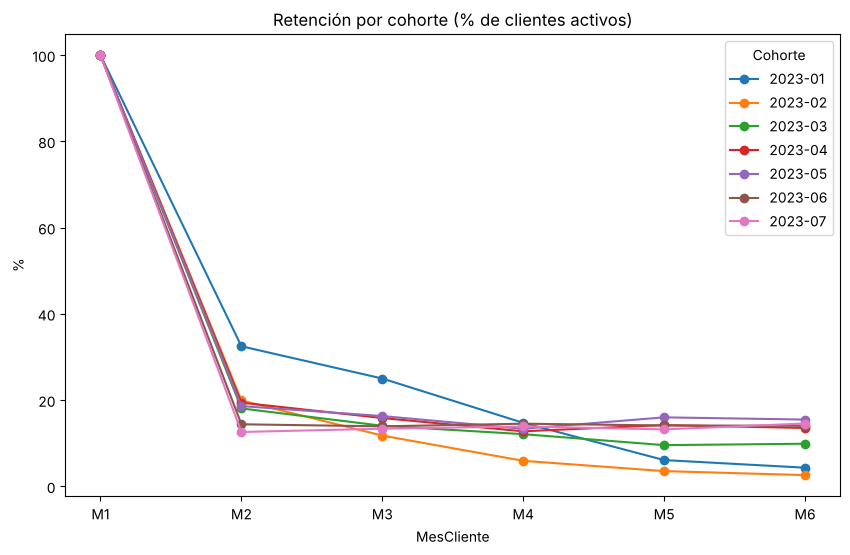

In [119]:
# Evolución de la retención de cada cohorte
ax = tabla_retencion_exacta.T.plot(kind='line', marker='o', figsize=(10, 6),
                                   title='Retención por cohorte (% de clientes activos)')
ax.set_ylabel('%')
ax.legend(title='Cohorte')
plt.show()

Lectura del gráfico:

- La gran caída está en **M2**: de cada 100 clientes nuevos, solo unos 21 vuelven a comprar el mes siguiente.
- A partir de M3 las cohortes de abril a julio se **estabilizan** en torno al 13-16 % (marzo, algo por debajo, en torno al 10-12 %): un núcleo de clientes que sigue comprando.
- Las cohortes de enero y febrero, en cambio, siguen cayendo hasta el 3-4 %.

In [120]:
# Retención global en el último mes estudiado (M6)
total_retenidos_final = tabla_cohortes['M6'].sum()
tasa_retencion_global = total_retenidos_final / total_inicial
tasa_retencion_global

np.float64(0.09862880211596019)

A los 6 meses sigue comprando el **9,9 %** de los clientes.

**Código de cohortes unificado**

```python
productos['MesTransaccion'] = productos['Fecha'].dt.to_period('M')
productos['MesCohorte'] = productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')

resultados = productos[productos['MesCohorte'] <= '2023-07'].copy()
meses_desde_cohorte = (resultados['MesTransaccion'] - resultados['MesCohorte']).apply(lambda x: x.n)
resultados_filtrados = resultados[meses_desde_cohorte <= 5].copy()
resultados_filtrados['MesCliente'] = 'M' + (meses_desde_cohorte[meses_desde_cohorte <= 5] + 1).astype(str)
resultados_filtrados['MesTransaccion'] = resultados_filtrados['MesTransaccion'].dt.to_timestamp()
resultados_filtrados['MesCohorte'] = resultados_filtrados['MesCohorte'].dt.to_timestamp()

tabla_cohortes = pd.pivot_table(resultados_filtrados, index='MesCohorte', columns='MesCliente',
                                values='ID_Cliente', aggfunc='nunique').fillna(0).astype(int)
tabla_retencion_exacta = tabla_cohortes.div(tabla_cohortes['M1'], axis=0) * 100
```

## 5. LTV y CAC (`04_LTV`)

- **LTV** (*Lifetime Value*): lo que deja un cliente a lo largo de su vida. Aquí se mide en sus **6 primeros meses**.
- **CAC** (*Customer Acquisition Cost*): lo que costó captarlo.

Si LTV > CAC, el cliente es rentable. La pregunta clave es **en qué mes** el valor acumulado supera el CAC (el **punto muerto**).

### 5.1 Venta media por cohorte y mes de cliente

In [121]:
tabla_venta_media = resultados_filtrados.groupby(['MesCohorte', 'MesCliente']).agg(
    clientes_unicos=('ID_Cliente', 'nunique'),   # clientes activos ese mes
    ventas_totales=('Total_Venta', 'sum'),        # lo que compraron ese mes
).reset_index()

# Compra media de un cliente ACTIVO ese mes
tabla_venta_media['compra_media_mes'] = tabla_venta_media['ventas_totales'] / tabla_venta_media['clientes_unicos']
tabla_venta_media

,MesCohorte,MesCliente,clientes_unicos,ventas_totales,compra_media_mes
0,2023-01-01,M1,3114,207036.09,66.485578
1,2023-01-01,M2,1011,75298.98,74.479703
2,2023-01-01,M3,778,49887.86,64.123213
3,2023-01-01,M4,458,26897.47,58.728100
4,2023-01-01,M5,189,10457.10,55.328571
5,2023-01-01,M6,134,7702.01,57.477687
6,2023-02-01,M1,2051,141044.28,68.768542
7,2023-02-01,M2,408,28712.95,70.374877
8,2023-02-01,M3,241,15143.70,62.836929
9,2023-02-01,M4,121,6453.77,53.336942


`compra_media_mes` es lo que gasta de media un cliente **que compra** ese mes, no un cliente cualquiera de la cohorte.

### 5.2 Pivotar: cohortes en filas, meses de vida en columnas

In [122]:
tabla_venta_media_pivotada = tabla_venta_media.pivot(index='MesCohorte', columns='MesCliente', values='compra_media_mes')
tabla_venta_media_pivotada.index = tabla_venta_media_pivotada.index.strftime('%Y-%m')
tabla_venta_media_pivotada

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01,66.485578,74.479703,64.123213,58.728100,55.328571,57.477687
2023-02,68.768542,70.374877,62.836929,53.336942,66.710694,47.971887
2023-03,57.673574,56.928846,51.428581,53.788506,52.976214,50.825070
2023-04,57.015791,55.928437,52.096140,45.611811,49.944136,51.766868
2023-05,56.813972,58.130922,57.358632,55.232122,52.937802,59.755069
2023-06,60.652765,53.485905,55.658768,50.169245,52.434126,51.331512
2023-07,62.303202,57.550680,63.172436,54.925556,58.689026,72.663235


### 5.3 LTV medio a 6 meses

LTV de una cohorte = Σ (compra media de los activos en Mk × retención en Mk), sumando de M1 a M6.

Es decir: lo que gasta un cliente activo, multiplicado por la probabilidad de que esté activo ese mes.

In [123]:
# Se usa la retención SIN redondear
tabla_ltv = tabla_venta_media_pivotada * tabla_retencion_exacta / 100
tabla_ltv['ltv'] = tabla_ltv.sum(axis=1)
tabla_ltv

MesCliente,M1,M2,M3,M4,M5,M6,ltv
MesCohorte,,,,,,,
2023-01,66.485578,24.180790,16.020507,8.637595,3.358092,2.473349,121.155912
2023-02,68.768542,13.999488,7.383569,3.146646,2.341867,1.239644,96.879756
2023-03,57.673574,10.278819,7.214287,6.499444,5.052361,5.011917,91.730403
2023-04,57.015791,10.841347,8.244170,5.813915,7.086830,6.996869,95.998923
2023-05,56.813972,10.809263,9.338595,7.359550,8.460069,9.242322,102.023770
2023-06,60.652765,7.687912,7.733559,7.279863,7.393176,7.202574,97.949849
2023-07,62.303202,7.243108,8.437414,7.618099,7.738108,10.575985,103.915916


**Corrección (error 7): el LTV medio debe ser ponderado.**

El original hacía `tabla_ltv.ltv.mean()`, que es la media simple de las 7 cohortes. Es el **mismo error** que el propio notebook de cohortes explica para la retención: cada cohorte pesa igual, tenga 1.168 o 3.114 clientes. Se comparan las dos:

In [124]:
# Media simple (lo que hacía el original, ahora sin redondeos intermedios)
ltv_simple = tabla_ltv['ltv'].mean()

# Media ponderada por el tamaño de cada cohorte
ltv_ponderado = np.average(tabla_ltv['ltv'], weights=tabla_cohortes['M1'])

# Comprobación: es lo mismo que el gasto medio por cliente en sus 6 primeros meses
ltv_directo = resultados_filtrados.groupby('ID_Cliente')['Total_Venta'].sum().mean()

print(f'LTV media simple de cohortes:  {ltv_simple:.2f} €   (el original daba 101,41 € al usar la retención redondeada)')
print(f'LTV ponderado por cohorte:     {ltv_ponderado:.2f} €')
print(f'Gasto medio por cliente en 6M: {ltv_directo:.2f} €')

LTV media simple de cohortes:  101.38 €   (el original daba 101,41 € al usar la retención redondeada)
LTV ponderado por cohorte:     102.76 €
Gasto medio por cliente en 6M: 102.76 €


El LTV ponderado coincide **exactamente** con el gasto medio por cliente en sus 6 primeros meses. No es casualidad:

compra media de los activos × retención = (ventas del mes / activos) × (activos / clientes de la cohorte) = ventas del mes / clientes de la cohorte.

Al sumar los 6 meses queda lo que ha gastado la cohorte entre su número de clientes. Por eso en el script final (paso 6) se comprueba que `Ventas_por_M1` suma 102,76 €. **El LTV correcto es 102,76 €, no 101,41 €.**

### 5.4 CAC medio

El CAC está en la tabla de clientes. En el original se hacía un `merge` con la tabla de transacciones y luego `groupby(...).first()` para volver a una fila por cliente. Se llega a lo mismo tomando directamente los clientes que están en el estudio:

In [125]:
ids_estudio = resultados_filtrados['ID_Cliente'].unique()
cac_cliente = clientes.set_index('ID_Cliente').loc[ids_estudio, 'CAC']

cac_medio = cac_cliente.mean()
print(f'CAC medio de los {len(cac_cliente)} clientes del estudio: {cac_medio:.2f} €')
print(f'CAC mediano: {cac_cliente.median():.2f} €')

CAC medio de los 14367 clientes del estudio: 69.44 €
CAC mediano: 47.53 €


In [126]:
# El merge del original también se hace, porque el tablón final necesita el CAC en cada fila
resultados_filtrados = resultados_filtrados.merge(clientes[['ID_Cliente', 'CAC']], on='ID_Cliente', how='left')

# Comprobación: el mismo CAC medio por los dos caminos
resultados_filtrados.groupby('ID_Cliente')['CAC'].first().mean()

np.float64(69.44205818890514)

### 5.5 Evolución del cliente medio frente al CAC

Valor acumulado del cliente medio mes a mes, frente a la línea del CAC medio.

**Mejoras respecto a la función original `evolucion_cliente`:**

- El original seleccionaba las columnas acumuladas con `df.iloc[:, 7:13]`, por **posición**. Si cambia el número de columnas de la tabla, coge las que no son, sin dar ningún error. Aquí se usan por nombre, con `cumsum`.
- El original **modificaba la tabla que recibía** (le añadía 6 columnas `_acum`). Aquí la función trabaja sobre una copia.
- La media era también la **media simple de cohortes**. Aquí se pondera por el tamaño de cada cohorte, igual que en 5.3.
- La línea del CAC tenía etiqueta pero faltaba `plt.legend()`, así que la leyenda no se veía. Además el CAC salía con 14 decimales.
- `plt.ylim(0, 150)` era fijo: si el LTV pasaba de 150 €, la curva se cortaba. Aquí el límite se ajusta solo.

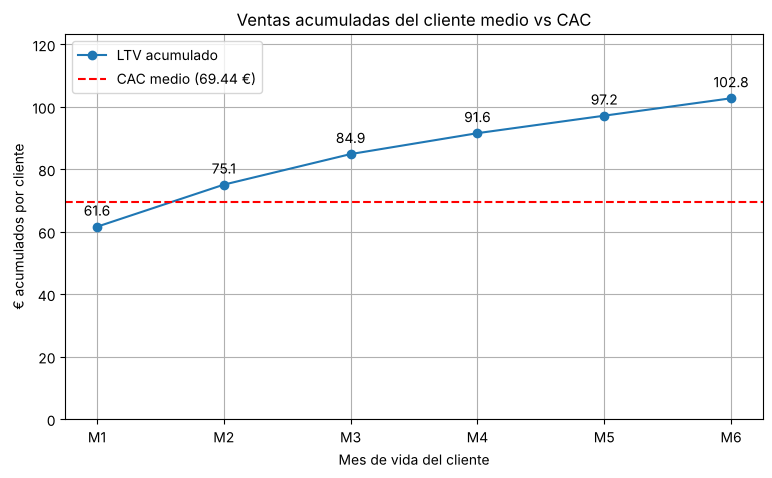

M1     61.61
M2     75.09
M3     84.89
M4     91.58
M5     97.18
M6    102.76
dtype: float64

In [127]:
MESES = ['M1', 'M2', 'M3', 'M4', 'M5', 'M6']

def evolucion_cliente(df, cac, pesos=None, titulo='Evolución del cliente medio', etiqueta='LTV acumulado'):
    # Valor acumulado medio por mes de vida, comparado con el CAC. Devuelve la serie acumulada.
    acumulado = df[MESES].cumsum(axis=1)   # M1, M1+M2, M1+M2+M3...
    if pesos is None:
        evolucion = acumulado.mean()
    else:
        evolucion = pd.Series(np.average(acumulado, axis=0, weights=pesos), index=MESES)

    plt.figure(figsize=(9, 5))
    plt.plot(MESES, evolucion.values, marker='o', label=etiqueta)
    plt.axhline(y=cac, color='r', linestyle='--', label=f'CAC medio ({cac:.2f} €)')
    for mes, valor in evolucion.items():
        plt.annotate(f'{valor:.1f}', (mes, valor), textcoords='offset points', xytext=(0, 8), ha='center')
    plt.ylim(0, max(evolucion.max(), cac) * 1.2)
    plt.title(titulo)
    plt.xlabel('Mes de vida del cliente')
    plt.ylabel('€ acumulados por cliente')
    plt.grid(True)
    plt.legend()
    plt.show()
    return evolucion

evolucion_ventas = evolucion_cliente(tabla_ltv, cac_medio, pesos=tabla_cohortes['M1'],
                                     titulo='Ventas acumuladas del cliente medio vs CAC')
evolucion_ventas.round(2)

Con **ventas**, el cliente medio supera el CAC en el **segundo mes** (75,1 € frente a 69,4 €). Es la conclusión del original.

### 5.6 Mejora: LTV con margen (error 8)

Hay un problema de fondo: el CAC se paga con **margen**, no con ventas. Si un cliente compra 100 € de productos que a la empresa le cuestan 70 €, solo quedan 30 € para pagar lo que costó captarlo. Comparar ventas con CAC hace que los clientes parezcan rentables mucho antes de serlo.

Se repite exactamente el mismo cálculo con `Margen` en lugar de `Total_Venta`:

LTV de ventas a 6 meses: 102.76 €
LTV de margen a 6 meses: 30.93 €
CAC medio:               69.44 €
Ratio LTV/CAC con ventas: 1.48   con margen: 0.45


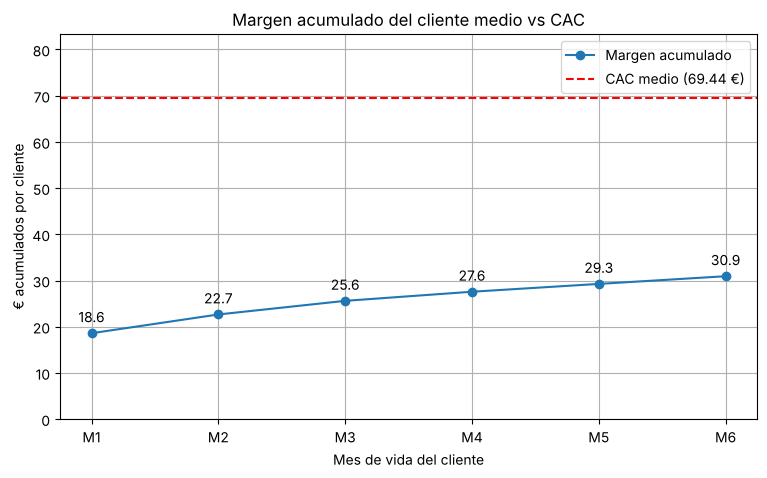

In [128]:
# Margen por cohorte y mes de vida, dividido entre los clientes de la cohorte (= compra media × retención)
margen_cohorte_mes = resultados_filtrados.pivot_table(index='MesCohorte', columns='MesCliente', values='Margen', aggfunc='sum')
margen_cohorte_mes.index = margen_cohorte_mes.index.strftime('%Y-%m')
tabla_ltv_margen = margen_cohorte_mes.div(tabla_cohortes['M1'], axis=0)
tabla_ltv_margen['ltv'] = tabla_ltv_margen[MESES].sum(axis=1)

ltv_margen = resultados_filtrados.groupby('ID_Cliente')['Margen'].sum().mean()
print(f'LTV de ventas a 6 meses: {ltv_directo:.2f} €')
print(f'LTV de margen a 6 meses: {ltv_margen:.2f} €')
print(f'CAC medio:               {cac_medio:.2f} €')
print(f'Ratio LTV/CAC con ventas: {ltv_directo / cac_medio:.2f}   con margen: {ltv_margen / cac_medio:.2f}')

evolucion_margen = evolucion_cliente(tabla_ltv_margen, cac_medio, pesos=tabla_cohortes['M1'],
                                     titulo='Margen acumulado del cliente medio vs CAC', etiqueta='Margen acumulado')

In [129]:
# ¿Qué porcentaje de clientes ha recuperado su propio CAC a los 6 meses?
por_cliente = resultados_filtrados.groupby('ID_Cliente').agg(ventas=('Total_Venta', 'sum'), margen=('Margen', 'sum'), CAC=('CAC', 'first'))
print(f"Clientes con ventas >= su CAC: {(por_cliente['ventas'] >= por_cliente['CAC']).mean() * 100:.1f} %")
print(f"Clientes con margen >= su CAC: {(por_cliente['margen'] >= por_cliente['CAC']).mean() * 100:.1f} %")

Clientes con ventas >= su CAC: 60.9 %
Clientes con margen >= su CAC: 27.5 %


**El resultado cambia la conclusión del proyecto.** Con margen, el cliente medio **no recupera el CAC en 6 meses**: aporta 30,9 € de margen frente a 69,4 € de CAC (un ratio LTV/CAC de 0,45). Solo el 27 % de los clientes ha devuelto lo que costó captarlo, frente al 61 % que parecía con ventas.

En M6 cada cliente de la cohorte aporta solo 1,66 € de margen al mes. A ese ritmo harían falta unos **23 meses más** ((69,44 − 30,93) / 1,66) para llegar al punto muerto, es decir, casi 2 años y medio de vida del cliente en total. La recomendación de negocio pasa de "es rentable desde el mes 2" a **"hay que bajar el CAC o mejorar la repetición; si no, cada cliente nuevo hace perder dinero en su primer medio año"**.

El análisis por perfiles de los apartados siguientes se hace con **ventas**, como en el original, para poder comparar con el dashboard. Con margen, todas las curvas quedarían por debajo del CAC.

### 5.7 Plan de Acción 1: pre-captación

Objetivo: ver con qué perfiles sociodemográficos se recupera antes el CAC, para decidir **en quién invertir** la captación.

Se usa una cohorte reciente y completa: **junio de 2023**.

In [130]:
# Clientes de la cohorte 2023-06
clientes_c6 = resultados_filtrados[resultados_filtrados['MesCohorte'] == '2023-06-01']
clientes_c6

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,Margen,MesTransaccion,MesCohorte,MesCliente,CAC
20,8,2023-06-21,30687,LPF,IP5IL,2.52,6.0,4.89,29.34,14.22,2023-06-01,2023-06-01,M1,70.91
113,42,2023-06-03,27726,X52,GBFC5,5.87,3.0,7.85,23.55,5.94,2023-06-01,2023-06-01,M1,75.46
114,42,2023-09-23,45992,3WV,R6HKE,3.16,3.0,5.37,16.11,6.63,2023-09-01,2023-06-01,M4,75.46
115,42,2023-09-23,45992,1L6,MGZ43,9.17,3.0,17.13,51.39,23.88,2023-09-01,2023-06-01,M4,75.46
132,45,2023-06-06,28118,OXH,VU316,2.11,7.0,3.11,21.77,7.00,2023-06-01,2023-06-01,M1,36.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54379,1331,2023-06-30,32363,SIM,K1R89,11.42,3.0,14.70,44.10,9.84,2023-06-01,2023-06-01,M1,88.13
54382,4410,2023-06-14,29625,NX3,A9BRM,2.06,7.0,2.73,19.11,4.69,2023-06-01,2023-06-01,M1,10.78
54386,17228,2023-06-12,29249,R6E,B4KFE,4.84,5.0,5.62,28.10,3.90,2023-06-01,2023-06-01,M1,120.50
54403,17354,2023-06-29,32041,01F,RVG1H,1.47,3.0,1.68,5.04,0.63,2023-06-01,2023-06-01,M1,26.46


In [131]:
# Venta de cada cliente en cada mes de vida
ltv_real_clientes_c6 = clientes_c6.groupby(['ID_Cliente', 'MesCliente'])['Total_Venta'].sum().reset_index()
ltv_real_clientes_c6

,ID_Cliente,MesCliente,Total_Venta
0,8,M1,29.34
1,42,M1,23.55
2,42,M4,67.50
3,45,M1,147.03
4,67,M1,264.66
...,...,...,...
2492,22179,M5,46.30
2493,22206,M1,76.68
2494,22206,M5,124.22
2495,22212,M1,3.96


In [132]:
# Una fila por cliente y una columna por mes; los meses sin compra son 0
tabla_ltv_real_clientes_c6 = ltv_real_clientes_c6.pivot(index='ID_Cliente', columns='MesCliente', values='Total_Venta').fillna(0)
tabla_ltv_real_clientes_c6['ltv_real'] = tabla_ltv_real_clientes_c6[MESES].sum(axis=1)
tabla_ltv_real_clientes_c6

MesCliente,M1,M2,M3,M4,M5,M6,ltv_real
ID_Cliente,,,,,,,
8,29.34,0.00,0.0,0.0,0.00,0.0,29.34
42,23.55,0.00,0.0,67.5,0.00,0.0,91.05
45,147.03,0.00,0.0,0.0,0.00,0.0,147.03
67,264.66,0.00,0.0,0.0,0.00,0.0,264.66
157,7.29,0.00,0.0,0.0,0.00,0.0,7.29
...,...,...,...,...,...,...,...
22176,24.96,0.00,0.0,0.0,0.00,0.0,24.96
22179,35.32,31.76,0.0,0.0,46.30,0.0,113.38
22206,76.68,0.00,0.0,0.0,124.22,0.0,200.90


`fillna(0)` es correcto aquí: si un cliente no compró en M3, su venta en M3 **es 0**, no un dato desconocido. Es el caso contrario al de los nulos de clientes del EDA, donde el dato sí falta.

**Unir datos sociodemográficos**

In [133]:
sociodemo = clientes[['ID_Cliente', 'Genero', 'Nivel_Educativo', 'Ocupacion', 'Tamano_Hogar', 'CAC']]

tabla_ltv_real_clientes_c6_completa = tabla_ltv_real_clientes_c6.merge(sociodemo, on='ID_Cliente', how='left')
print('Nulos tras el merge:', tabla_ltv_real_clientes_c6_completa.isna().sum().sum())
tabla_ltv_real_clientes_c6_completa

Nulos tras el merge: 0


,ID_Cliente,M1,M2,M3,M4,M5,M6,ltv_real,Genero,Nivel_Educativo,Ocupacion,Tamano_Hogar,CAC
0,8,29.34,0.00,0.0,0.0,0.00,0.0,29.34,Mujer,Bachillerato,Autónomo,4-5 personas,70.91
1,42,23.55,0.00,0.0,67.5,0.00,0.0,91.05,Mujer,Máster,Autónomo,2-3 personas,75.46
2,45,147.03,0.00,0.0,0.0,0.00,0.0,147.03,Hombre,Máster,Desconocido,4-5 personas,36.08
3,67,264.66,0.00,0.0,0.0,0.00,0.0,264.66,Mujer,Universitario,Empleado,2-3 personas,70.00
4,157,7.29,0.00,0.0,0.0,0.00,0.0,7.29,Hombre,Universitario,Desempleado,4-5 personas,50.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,22176,24.96,0.00,0.0,0.0,0.00,0.0,24.96,Mujer,Educación básica,Empleado,4-5 personas,54.88
1457,22179,35.32,31.76,0.0,0.0,46.30,0.0,113.38,Mujer,Desconocido,Desempleado,2-3 personas,31.54
1458,22206,76.68,0.00,0.0,0.0,124.22,0.0,200.90,Mujer,Universitario,Desconocido,2-3 personas,24.46
1459,22212,3.96,0.00,0.0,0.0,0.00,0.0,3.96,Mujer,Sin estudios,Desconocido,2-3 personas,4.27


**Corrección (error 9):** ahora no hay ningún `NaN` en Ocupación ni en Nivel Educativo. En el original sí los había (por el error 1), y los bucles de abajo generaban un gráfico para la "categoría" `NaN`, que salía vacío porque `df[col] == NaN` nunca es verdadero.

In [134]:
# CAC medio de esta cohorte
cac_medio_c6 = tabla_ltv_real_clientes_c6_completa['CAC'].mean()
cac_medio_c6

np.float64(71.23369609856262)

**Punto muerto de cada perfil frente al CAC medio**

**Mejora:** el original dibujaba **un gráfico por categoría** (6 de Nivel Educativo y 6 de Ocupación, cada uno por separado), lo que obliga a ir pasando de uno a otro para comparar. Aquí se dibujan **todas las categorías de una variable en un solo gráfico** y se añade una tabla con el número de clientes y el **mes en que cada perfil supera el CAC**.

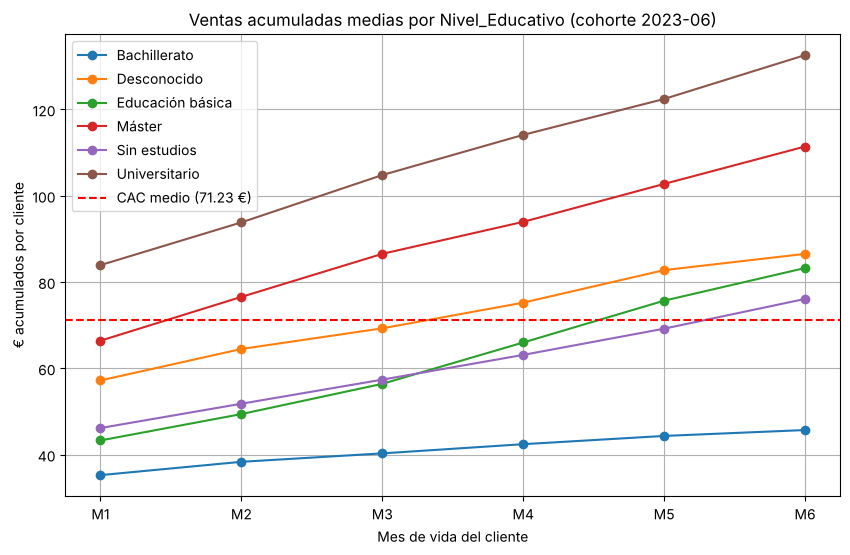

,clientes,ltv_6M,mes_punto_muerto
Nivel_Educativo,,,
Universitario,452,132.60,M1
Máster,303,111.42,M2
Desconocido,123,86.54,M4
Educación básica,257,83.26,M5
Sin estudios,81,76.10,M6
Bachillerato,245,45.72,No alcanza


In [135]:
def analisis_punto_muerto(df, variable, cac):
    # Ventas acumuladas medias por categoría de 'variable', frente al CAC
    acumulado = df[MESES].cumsum(axis=1)
    acumulado[variable] = df[variable].values
    medias = acumulado.groupby(variable)[MESES].mean()

    plt.figure(figsize=(10, 6))
    for categoria, fila in medias.iterrows():
        plt.plot(MESES, fila.values, marker='o', label=categoria)
    plt.axhline(y=cac, color='red', linestyle='--', label=f'CAC medio ({cac:.2f} €)')
    plt.title(f'Ventas acumuladas medias por {variable} (cohorte 2023-06)')
    plt.xlabel('Mes de vida del cliente')
    plt.ylabel('€ acumulados por cliente')
    plt.grid(True)
    plt.legend()
    plt.show()

    # Mes en que la curva supera el CAC (o 'No alcanza' si no lo hace en 6 meses)
    resumen = pd.DataFrame({'clientes': df[variable].value_counts()})
    resumen['ltv_6M'] = medias['M6']
    resumen['mes_punto_muerto'] = medias.apply(lambda fila: next((m for m in MESES if fila[m] >= cac), 'No alcanza'), axis=1)
    return resumen.sort_values('ltv_6M', ascending=False).round(2)

analisis_punto_muerto(tabla_ltv_real_clientes_c6_completa, 'Nivel_Educativo', cac_medio_c6)

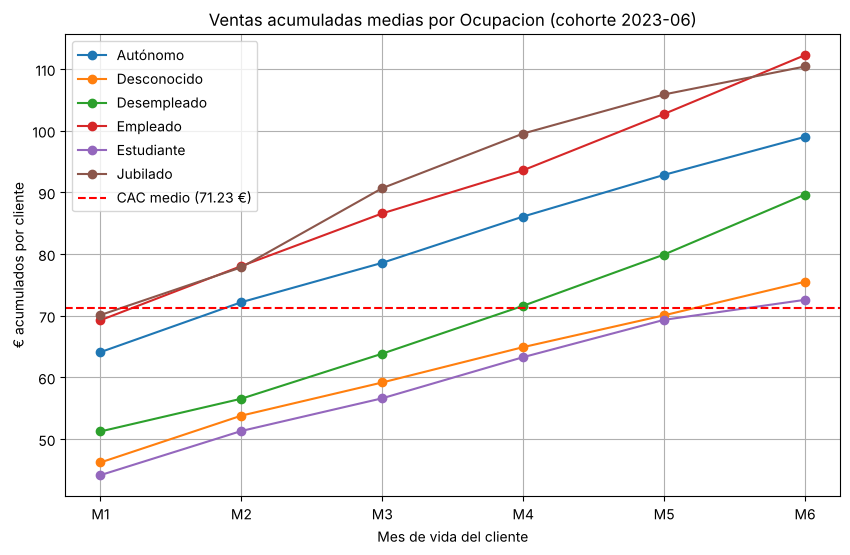

,clientes,ltv_6M,mes_punto_muerto
Ocupacion,,,
Empleado,428,112.26,M2
Jubilado,177,110.42,M2
Autónomo,339,99.02,M2
Desempleado,228,89.66,M4
Desconocido,178,75.53,M6
Estudiante,111,72.59,M6


In [136]:
analisis_punto_muerto(tabla_ltv_real_clientes_c6_completa, 'Ocupacion', cac_medio_c6)

Hay perfiles que, de media, superan el CAC en el **mes 1 o 2** y otros que tardan más o no llegan en 6 meses. La idea del original sigue en pie: asignar el presupuesto de captación de forma más estratégica, invirtiendo más en los perfiles que recuperan antes el CAC y menos en los que no lo recuperan.

Dos precauciones:

1. Algunos grupos son **pequeños** (la columna `clientes` lo muestra). Con menos de 100 clientes, unos pocos compradores grandes mueven mucho la media.
2. Esto es con **ventas**. Con margen (apartado 5.6), ningún perfil llegaría al CAC en 6 meses.

### 5.8 Plan de Acción 2: post-captación (LTV predictivo)

Idea del original: cuando llega un cliente nuevo, todavía no se sabe cuánto va a gastar. Pero sí se conocen sus datos sociodemográficos, así que se le **predice** el LTV medio de los clientes con su mismo perfil (Nivel Educativo + Ocupación + Tamaño de Hogar). Si la predicción es buena, se pueden personalizar las campañas desde el primer día.

Para saber si la predicción sirve hay que compararla con una **referencia sin modelo**: predecir a todos el LTV medio general. El modelo solo aporta algo si se equivoca **menos** que esa referencia.

**Primero, lo que hacía el original y por qué está mal (errores 10 y 11):**

In [137]:
# LTV a 6 meses de cada cliente del estudio (todas las cohortes)
ltv_clientes = resultados_filtrados.groupby('ID_Cliente')[['Total_Venta']].sum()
ltv_clientes.columns = ['ltv']
ltv_clientes_socio = ltv_clientes.merge(sociodemo, on='ID_Cliente', how='left')

# LTV medio por perfil, calculado con TODAS las cohortes (incluida la 2023-06)
perfil = ['Nivel_Educativo', 'Ocupacion', 'Tamano_Hogar']
ltv_socio = ltv_clientes_socio.groupby(perfil).agg(ltv_medio=('ltv', 'mean')).reset_index()
venta_media = ltv_clientes['ltv'].mean()

original = tabla_ltv_real_clientes_c6_completa[['ID_Cliente'] + perfil + ['ltv_real', 'CAC']].merge(ltv_socio, on=perfil, how='left')
original = original.rename(columns={'ltv_medio': 'ltv_predicho'})

# Cálculo ORIGINAL (incorrecto): las dos "distancias" se miden contra la media general
error_real_original = (original['ltv_real'] - venta_media).abs().mean()
error_predicho_original = (original['ltv_predicho'] - venta_media).abs().mean()
print(f'Original. "Error real":     {error_real_original:.2f} €')
print(f'Original. "Error predicho": {error_predicho_original:.2f} €   <- no es un error de predicción')

Original. "Error real":     74.12 €
Original. "Error predicho": 17.95 €   <- no es un error de predicción


Por qué está mal:

- `|ltv_real − media|` sí es el error de la referencia: lo que te equivocas si a todos les predices la media.
- `|ltv_predicho − media|` **no mide ningún error**: es la distancia entre dos predicciones, la del modelo y la media. Las medias por perfil siempre se parecen a la media general, porque son medias de grupos grandes. Por eso este número sale pequeño **aunque el modelo no acierte nada**: aquí 17,95 €; en el original 18,67 €, porque los nulos sin imputar (error 1) cambiaban algunos perfiles. La conclusión "nuestra estrategia minimiza con diferencia el error" no se sostiene.
- Además, las medias por perfil se calcularon **incluyendo a los clientes de la cohorte 2023-06**, que son justo los que se evalúan. Es *data leakage*: el modelo ya conoce parte de la respuesta.

**Cálculo correcto:**

1. Se "entrena" (se calculan las medias por perfil) solo con las **otras 6 cohortes**.
2. Se predice a los clientes de la cohorte **2023-06**, que el modelo no ha visto.
3. Se compara el error del modelo, `|real − predicho|`, con el error de la referencia, `|real − media|`. Es el **MAE** (*Mean Absolute Error*, error absoluto medio).

In [138]:
es_c6 = ltv_clientes_socio['ID_Cliente'].isin(tabla_ltv_real_clientes_c6.index)
entrenamiento = ltv_clientes_socio[~es_c6]    # cohortes ene-may y jul
prueba = ltv_clientes_socio[es_c6]            # cohorte 2023-06

# "Modelo": LTV medio por perfil, aprendido solo con entrenamiento
ltv_socio_train = entrenamiento.groupby(perfil).agg(ltv_predicho=('ltv', 'mean'), clientes_perfil=('ltv', 'size')).reset_index()
media_train = entrenamiento['ltv'].mean()

evaluacion = prueba.merge(ltv_socio_train, on=perfil, how='left')
# Si un perfil no aparece en entrenamiento, se le predice la media general
evaluacion['ltv_predicho'] = evaluacion['ltv_predicho'].fillna(media_train)

evaluacion['error_referencia'] = (evaluacion['ltv'] - media_train).abs()
evaluacion['error_modelo'] = (evaluacion['ltv'] - evaluacion['ltv_predicho']).abs()

mae_ref = evaluacion['error_referencia'].mean()
mae_modelo = evaluacion['error_modelo'].mean()
print(f'Clientes evaluados (cohorte 2023-06): {len(evaluacion)}')
print(f'MAE prediciendo a todos la media:     {mae_ref:.2f} €')
print(f'MAE prediciendo la media de su perfil: {mae_modelo:.2f} €')
print(f'Mejora: {(1 - mae_modelo / mae_ref) * 100:.1f} %')
evaluacion[['ID_Cliente'] + perfil + ['ltv', 'ltv_predicho', 'error_referencia', 'error_modelo']].head(10)

Clientes evaluados (cohorte 2023-06): 1461
MAE prediciendo a todos la media:     74.31 €
MAE prediciendo la media de su perfil: 73.55 €
Mejora: 1.0 %


,ID_Cliente,Nivel_Educativo,Ocupacion,Tamano_Hogar,ltv,ltv_predicho,error_referencia,error_modelo
0,8,Bachillerato,Autónomo,4-5 personas,29.34,98.750940,73.960526,69.410940
1,42,Máster,Autónomo,2-3 personas,91.05,177.951813,12.250526,86.901813
2,45,Máster,Desconocido,4-5 personas,147.03,66.156304,43.729474,80.873696
3,67,Universitario,Empleado,2-3 personas,264.66,112.347788,161.359474,152.312212
4,157,Universitario,Desempleado,4-5 personas,7.29,86.678816,96.010526,79.388816
5,175,Bachillerato,Estudiante,1 persona,10.64,119.984167,92.660526,109.344167
6,236,Máster,Autónomo,2-3 personas,125.11,177.951813,21.809474,52.841813
7,278,Educación básica,Desempleado,2-3 personas,22.08,62.826018,81.220526,40.746018
8,298,Máster,Estudiante,4-5 personas,89.68,111.945455,13.620526,22.265455
9,309,Bachillerato,Jubilado,2-3 personas,17.96,107.544212,85.340526,89.584212


In [139]:
# ¿Por qué el perfil predice tan poco? Comparamos cuánto varía el LTV ENTRE perfiles y DENTRO de cada perfil
print(f"Desviación típica del LTV entre clientes:          {entrenamiento['ltv'].std():.2f} €")
print(f"Desviación típica de las medias de cada perfil:    {ltv_socio_train['ltv_predicho'].std():.2f} €")
print(f"Perfiles distintos: {len(ltv_socio_train)}; clientes por perfil: mínimo {ltv_socio_train['clientes_perfil'].min()}, mediana {ltv_socio_train['clientes_perfil'].median():.0f}")

Desviación típica del LTV entre clientes:          103.70 €
Desviación típica de las medias de cada perfil:    22.54 €
Perfiles distintos: 108; clientes por perfil: mínimo 3, mediana 50


**Conclusión corregida:** predecir con la media del perfil reduce el error solo un **1 %** (de 74,3 € a 73,5 €). En la práctica, el perfil sociodemográfico **casi no ayuda a predecir** cuánto va a gastar un cliente. Los clientes de un mismo perfil se diferencian entre sí mucho más de lo que se diferencian unos perfiles de otros. Además, varios perfiles tienen muy pocos clientes y su media es poco fiable.

Para campañas de fidelización personalizadas son mejores predictores el **propio comportamiento** del cliente (cuánto gastó en su primera compra, qué categoría compró, si repitió en el primer mes) que su perfil sociodemográfico. Ese sería el siguiente paso natural: un modelo con variables de comportamiento, evaluado igual, sobre una cohorte que no se ha usado para entrenar.

**Código LTV unificado**

```python
cac_medio = clientes.set_index('ID_Cliente').loc[resultados_filtrados['ID_Cliente'].unique(), 'CAC'].mean()
resultados_filtrados = resultados_filtrados.merge(clientes[['ID_Cliente', 'CAC']], on='ID_Cliente', how='left')

ltv_cliente = resultados_filtrados.groupby('ID_Cliente').agg(ltv=('Total_Venta', 'sum'), ltv_margen=('Margen', 'sum'))
```

## 6. Tablones para Tableau (`05_Script_final`)

El script final junta todo y genera tres archivos para el dashboard:

| Archivo | Una fila por... | Para qué |
|---|---|---|
| `tablon_analitico_clientes.csv` | línea de compra (ventana de 6 meses) | Análisis detallado: por producto, mes, cohorte... |
| `tablon_cliente.csv` | cliente | Segmentos, LTV, CAC, perfil |
| `ltv_mes.csv` | mes de vida (M1...M6) | Curva de LTV acumulado |

**Corrección (error 13).** El `05_Script_final` original tiene las celdas ejecutadas fuera de orden (contadores 15, 16, 17, 18, 5, 6, 6, 7, 15, 13, 14). La tabla `tablon_cliente` que se ve guardada (contador 6) es de una ejecución **anterior** a la del código actual (contador 15), y por eso muestra "Dudosos" en todos los clientes, incluso en el 1, que es "En Riesgo" (r = 1, f = 1, m = 2). Con el código actual y los datos actuales los segmentos salen bien. Este notebook se ejecuta de principio a fin, así que lo que se ve es lo que hace el código.

Las variables `productos`, `clientes`, `rfm`, `resultados_filtrados` y el CAC ya están calculados en los pasos anteriores. En el original el script lo repetía todo desde cero; aquí no hace falta.

### 6.1 LTV por cliente

In [140]:
ltv_cliente = resultados_filtrados.groupby('ID_Cliente').agg(ltv=('Total_Venta', 'sum'), ltv_margen=('Margen', 'sum'))
ltv_cliente

,ltv,ltv_margen
ID_Cliente,,
1,65.16,16.32
2,68.31,27.39
3,24.60,5.00
4,139.85,53.97
5,143.81,32.10
...,...,...
22232,21.00,4.40
22233,23.76,3.48
22234,221.28,51.11


**Mejora:** se añade `ltv_margen` para que el dashboard pueda mostrar también el LTV de margen (apartado 5.6).

### 6.2 Tablón analítico (una fila por línea de compra)

In [141]:
sociodemo = clientes[['ID_Cliente', 'Genero', 'Nivel_Educativo', 'Ocupacion', 'Tamano_Hogar']]

tablon_analitico = (
    resultados_filtrados
    .merge(rfm, on='ID_Cliente', how='left')
    .merge(sociodemo, on='ID_Cliente', how='left')
    .merge(ltv_cliente, on='ID_Cliente', how='left')
)

# Comprobación: los merges no han duplicado ni perdido filas
assert len(tablon_analitico) == len(resultados_filtrados)
print(tablon_analitico.shape)
tablon_analitico.head(3).T   # .T (traspuesta): con 28 columnas se lee mejor en vertical

(54405, 28)


,0,1,2
ID_Cliente,1,1,2
Fecha,2023-01-21 00:00:00,2023-01-21 00:00:00,2023-03-24 00:00:00
ID_Transaccion,3442,3442,14177
Categoria_Producto,0H2,N8U,TVL
Producto,6OUVC,CEBU8,2SLS0
Coste_Unitario,7.64,4.57,4.6
Cantidad,4.0,4.0,3.0
Precio_Unitario,10.5,5.79,7.77
Total_Venta,42.0,23.16,23.31
Margen,11.44,4.88,9.51


`assert` detiene la ejecución con un error si la condición es falsa. Es una forma barata de asegurarse de que un `merge` no ha multiplicado filas, por ejemplo si hubiera IDs repetidos en `rfm` o en `clientes`.

### 6.3 Tablón a nivel de cliente

El original comprobó qué columnas tienen un único valor por cliente (con `nunique`) y se quedó con esas, agregando con `first`. Se repite la comprobación:

In [142]:
# Conteo de valores únicos por columna para cada cliente
valores_unicos_cliente = tablon_analitico.groupby('ID_Cliente').nunique()

# Columnas con más de un valor en algún cliente: varían dentro del cliente y NO van en el tablón de cliente
print('Varían dentro del cliente:', list(valores_unicos_cliente.columns[(valores_unicos_cliente > 1).any()]))

Varían dentro del cliente: ['Fecha', 'ID_Transaccion', 'Categoria_Producto', 'Producto', 'Coste_Unitario', 'Cantidad', 'Precio_Unitario', 'Total_Venta', 'Margen', 'MesTransaccion', 'MesCliente']


In [143]:
tablon_cliente = tablon_analitico.groupby('ID_Cliente').agg({
    'MesCohorte': 'first',
    'CAC': 'first',
    'Recency': 'first',
    'Frequency': 'first',
    'Monetary': 'first',
    'r': 'first',
    'f': 'first',
    'm': 'first',
    'Segmento': 'first',
    'Genero': 'first',
    'Nivel_Educativo': 'first',
    'Ocupacion': 'first',
    'Tamano_Hogar': 'first',
    'ltv': 'first',
    'ltv_margen': 'first',
}).reset_index()

tablon_cliente

,ID_Cliente,MesCohorte,CAC,Recency,Frequency,Monetary,r,f,m,Segmento,Genero,Nivel_Educativo,Ocupacion,Tamano_Hogar,ltv,ltv_margen
0,1,2023-01-01,184.31,344,1,65.16,1,1,2,En Riesgo,Hombre,Universitario,Empleado,4-5 personas,65.16,16.32
1,2,2023-03-01,31.60,195,2,68.31,2,1,2,En Riesgo,Hombre,Sin estudios,Empleado,1 persona,68.31,27.39
2,3,2023-01-01,29.33,364,1,24.60,1,1,1,En Riesgo,Mujer,Bachillerato,Estudiante,4-5 personas,24.60,5.00
3,4,2023-07-01,63.67,52,2,139.85,5,1,3,Dudosos,Hombre,Bachillerato,Empleado,2-3 personas,139.85,53.97
4,5,2023-02-01,11.13,179,5,143.81,3,3,3,Prometedores,Mujer,Universitario,Estudiante,2-3 personas,143.81,32.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14362,22232,2023-06-01,48.37,193,1,21.00,2,1,1,En Riesgo,Hombre,Universitario,Autónomo,2-3 personas,21.00,4.40
14363,22233,2023-07-01,20.30,179,1,23.76,3,1,1,Dudosos,Mujer,Universitario,Empleado,2-3 personas,23.76,3.48
14364,22234,2023-05-01,81.66,142,2,221.28,3,1,4,Dudosos,Mujer,Máster,Jubilado,2-3 personas,221.28,51.11
14365,22235,2023-05-01,10.36,231,1,14.72,2,1,1,En Riesgo,Mujer,Bachillerato,Empleado,1 persona,14.72,5.28


**Corrección (error 16):** se añade `.reset_index()`. En el original `ID_Cliente` quedaba como índice, y al exportar con `index=False` **se perdía la columna `ID_Cliente`** del `tablon_cliente.csv`, así que en Tableau no había forma de identificar a cada cliente ni de cruzarlo con otra tabla.

In [144]:
tablon_cliente['CAC'].mean()

np.float64(69.44205818890514)

**Corrección (error 12): contar segmentos por clientes, no por filas.**

In [145]:
comparacion = pd.DataFrame({
    'filas_tablon_analitico (original)': tablon_analitico['Segmento'].value_counts(),
    'clientes (correcto)': tablon_cliente['Segmento'].value_counts(),
})
comparacion.sort_values('clientes (correcto)', ascending=False)

,filas_tablon_analitico (original),clientes (correcto)
Segmento,,
En Riesgo,10108,5951
Dudosos,26874,5791
Grandes Gastadores,8165,1409
Campeones,6424,555
Clientes Recientes,1177,474
Leales Potenciales,493,65
Clientes Leales,526,62
Clientes Rentables,501,39
Prometedores,137,21


El original contaba sobre `tablon_analitico`, donde cada cliente aparece **tantas veces como líneas de compra tenga**. Así, "Campeones" (clientes que compran mucho) salía con 6.424, cuando son 555 clientes: cada uno aporta muchas filas. Los recuentos por filas sobrerrepresentan a los que más compran.

**Corrección (error 14): el tablón mezcla dos periodos.** Hay que tenerlo presente al leer el dashboard:

In [146]:
print('Clientes en el RFM (todo 2023):', len(rfm))
print('Clientes en los tablones (cohortes ene-jul):', len(tablon_cliente))
print('Clientes que se quedan fuera (cohortes ago-dic):', len(rfm) - len(tablon_cliente))
print()
print('Monetary (todo 2023) vs ltv (6 primeros meses), media por cliente del tablón:')
print(tablon_cliente[['Monetary', 'ltv']].mean().round(2))

Clientes en el RFM (todo 2023): 20688
Clientes en los tablones (cohortes ene-jul): 14367
Clientes que se quedan fuera (cohortes ago-dic): 6321

Monetary (todo 2023) vs ltv (6 primeros meses), media por cliente del tablón:
Monetary    114.45
ltv         102.76
dtype: float64


- **Recency, Frequency, Monetary y Segmento** se calculan sobre **todo 2023**.
- **ltv** solo cuenta los **6 primeros meses** de vida de cada cliente.

Por eso `Monetary` ≥ `ltv` en cada cliente, y no son intercambiables. Y los 6.321 clientes captados de agosto a diciembre no están en los tablones: los segmentos del dashboard **no** representan a toda la base de clientes, sino solo a las cohortes de enero a julio.

### 6.4 Tablón de LTV por mes de vida

In [147]:
ltv_mes = tablon_analitico.groupby(['ID_Cliente', 'MesCliente']).agg({'Total_Venta': 'sum', 'Margen': 'sum'}).reset_index()

ltv_agrupado = ltv_mes.groupby('MesCliente').agg({'Total_Venta': 'sum', 'Margen': 'sum', 'ID_Cliente': 'nunique'})

# Base del estudio: todos los clientes (están todos en M1)
ltv_agrupado['M1'] = ltv_agrupado.loc['M1', 'ID_Cliente']

ltv_agrupado['Ventas_por_M1'] = ltv_agrupado['Total_Venta'] / ltv_agrupado['M1']
ltv_agrupado['Margen_por_M1'] = ltv_agrupado['Margen'] / ltv_agrupado['M1']
ltv_agrupado = ltv_agrupado.reset_index()
ltv_agrupado

,MesCliente,Total_Venta,Margen,ID_Cliente,M1,Ventas_por_M1,Margen_por_M1
0,M1,885178.76,267090.34,14367,14367,61.611941,18.590544
1,M2,193674.15,58325.73,3003,14367,13.480487,4.059701
2,M3,140703.96,42366.56,2390,14367,9.793552,2.948880
3,M4,96188.18,28317.95,1790,14367,6.695078,1.971041
4,M5,80492.23,24339.50,1495,14367,5.602577,1.694125
5,M6,80064.04,23916.02,1417,14367,5.572774,1.664650


In [148]:
# Comprobación: la suma da el LTV medio a 6 meses (ventas y margen)
print(f"Suma Ventas_por_M1: {ltv_agrupado['Ventas_por_M1'].sum():.2f} €")
print(f"Suma Margen_por_M1: {ltv_agrupado['Margen_por_M1'].sum():.2f} €")

Suma Ventas_por_M1: 102.76 €
Suma Margen_por_M1: 30.93 €


`Ventas_por_M1` = ventas del mes / clientes de M1. Es exactamente "compra media × retención" del apartado 5.3, y su suma vuelve a dar **102,76 €**: el LTV ponderado. El script final ya calculaba el LTV bien; el que estaba mal era el 101,41 € de `04_LTV`.

### 6.5 Exportar

**Corrección (error 15).** El original exportaba con `decimal=','`, pero dejaba el separador de columnas por defecto, que también es `,`. Pandas lo resuelve poniendo **cada número decimal entre comillas** (`"65,16"`) para que no se confunda con un cambio de columna. El archivo es técnicamente válido, pero depende de que la herramienta que lo lee respete las comillas, y algunas leen esos números como texto.

La solución estándar en España es **separador `;` y decimal `,`** (es lo que usa Excel en español). En Tableau, al conectar el archivo, hay que indicar que el separador de campos es punto y coma.

In [149]:
opciones_csv = dict(sep=';', decimal=',', index=False, encoding='utf-8-sig')

tablon_analitico.to_csv(RUTA / 'tablon_analitico_clientes.csv', **opciones_csv)
tablon_cliente.to_csv(RUTA / 'tablon_cliente.csv', **opciones_csv)
ltv_agrupado.to_csv(RUTA / 'ltv_mes.csv', **opciones_csv)

# Comprobación: se releen y se comparan con lo que había en memoria
for nombre, tabla in [('tablon_analitico_clientes.csv', tablon_analitico), ('tablon_cliente.csv', tablon_cliente), ('ltv_mes.csv', ltv_agrupado)]:
    releido = pd.read_csv(RUTA / nombre, sep=';', decimal=',', encoding='utf-8-sig')
    print(f'{nombre:32s} filas {len(releido):6d}  columnas {releido.shape[1]:2d}  iguales: {releido.shape == tabla.shape}')

tablon_analitico_clientes.csv    filas  54405  columnas 28  iguales: True
tablon_cliente.csv               filas  14367  columnas 16  iguales: True
ltv_mes.csv                      filas      6  columnas  7  iguales: True


- `encoding='utf-8-sig'` añade una marca al inicio del archivo para que Excel muestre bien las tildes y la ñ ("Máster", "Autónomo", "Tamaño").
- Las exportaciones se hacen **una sola vez**. En el original estaban repetidas: dentro del script y otra vez en tres celdas sueltas.
- Se elimina la celda `import sys; print(sys.executable)`, que mostraba la ruta del entorno de Anaconda con el nombre de tu usuario de Windows. Es un dato personal que no aporta nada en un portfolio público.

## Resumen

### Lo que dicen los datos

| Pregunta | Respuesta |
|---|---|
| ¿Cuántos clientes y compras? | 20.688 clientes, 43.644 transacciones (cliente + ticket) y 78.266 líneas en 2023 |
| ¿Cuánto es un ticket medio? | ≈ 49 € (1,8 productos). El "27,44 € por transacción" del original era por línea |
| ¿Repiten los clientes? | Poco: el 56 % compra **una sola vez** y casi la mitad lleva más de 6 meses sin comprar |
| ¿Están concentrados los ingresos? | No mucho: el 41,7 % de los clientes genera el 80 % de los ingresos |
| Retención | Cae al 21 % en M2 y al 9,9 % en M6 (media ponderada) |
| LTV a 6 meses | **102,76 €** de ventas y **30,93 €** de margen por cliente |
| CAC medio | 69,44 € (mediana 47,53 €) |
| ¿Se recupera el CAC? | Con ventas, en el mes 2. **Con margen, no se recupera en 6 meses** (ratio LTV/CAC = 0,45) |
| ¿Predice el perfil sociodemográfico el LTV? | Casi nada: el error baja solo un 1 % respecto a predecir la media |

### Recomendaciones (corregidas)

1. **El problema principal es la repetición.** Las campañas con más retorno son las que consiguen la **segunda compra** (Clientes Recientes y Dudosos con r = 5), porque el gran abandono está en M2.
2. **Revisar el CAC.** Con un margen bruto del 30 %, un cliente necesita gastar unos 230 € para devolver un CAC de 69 €, y el cliente medio gasta 103 € en 6 meses. O se reduce el CAC (sobre todo la cola de clientes captados muy caros) o se alarga la vida del cliente.
3. **Invertir la captación en los perfiles que antes llegan al punto muerto**, con prudencia en los grupos pequeños.
4. **No usar el perfil sociodemográfico para predecir el valor de un cliente.** Usar su comportamiento en las primeras semanas.

### Glosario rápido de pandas usado

| Función | Qué hace |
|---|---|
| `groupby(col).agg(nombre=(col, func))` | Agrupa y crea columnas resumen con nombre |
| `groupby(col).transform(func)` | Como `agg`, pero devuelve un valor por fila original (no reduce la tabla) |
| `pd.cut(serie, bins, labels)` | Corta una variable en tramos de límites fijos |
| `pd.qcut(serie, q)` | Corta en tramos con el mismo número de elementos (cuantiles) |
| `dt.to_period('M')` | Convierte una fecha en su mes |
| `pivot` / `pivot_table` | Pasa de formato largo a una tabla de doble entrada |
| `div(serie, axis=0)` | Divide cada fila por un valor distinto |
| `cumsum(axis=1)` | Suma acumulada a lo largo de las columnas |
| `merge(..., how='left')` | Une tablas conservando todas las filas de la izquierda |
| `np.average(valores, weights=pesos)` | Media ponderada |